### Load the KHS-2026 dataset

In [1]:
import pandas as pd
import os 

df = pd.read_csv("data.csv", encoding="latin-1")

print ("Dataset loaded successfully")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


Dataset loaded successfully
Shape: (6538, 2)

Columns:
['Text', 'Label']


In [2]:
df.head()

,Text,Label
0,Haja ya kuona watoto wa baba mbele mgomo ahadi...,2
1,tafadhali katiba ya ruto iruhusu maandamano ya...,2
2,hakika ardhi linganisha sifuna malala,2
3,kinyume cha sheria silly linganisha malala sif...,2
4,hornbill inayofanya kelele kila siku inayoitwa...,2


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6538 entries, 0 to 6537
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Text    6538 non-null   str  
 1   Label   6538 non-null   str  
dtypes: str(2)
memory usage: 759.7 KB


In [4]:
df.isnull().sum()

Text     0
Label    0
dtype: int64

### Label Distribution

In [5]:
print("Unique labels:")
print(df['Label'].unique())

print("\nLabel distribution:")
print(df['Label'].value_counts())

print("\nLabel percentages:")
print(df['Label'].value_counts(normalize=True) * 100)

Unique labels:
<ArrowStringArray>
['2', '0', '0  / Humorous', '0  / 1', '1']
Length: 5, dtype: str

Label distribution:
Label
0                4316
1                1590
2                 630
0  / Humorous       1
0  / 1              1
Name: count, dtype: int64

Label percentages:
Label
0                66.014072
1                24.319364
2                 9.635974
0  / Humorous     0.015295
0  / 1            0.015295
Name: proportion, dtype: float64


### Check for duplicates 

In [6]:
# Check for duplicated rows 
print("Number of duplicate rows:" , df.duplicated().sum())

#check for duplicated texts 
print("Number of duplicated texts:", df.duplicated(subset='Text').sum())

Number of duplicate rows: 190
Number of duplicated texts: 199


In [7]:
# Display examples of labels in each class
for label in df['Label'].unique():
    print(f"\n" + "=" *60)
    print("LABEL:", label)
    print("=" *60)

    display(df[df['Label'] == label]['Text'].head(5))


LABEL: 2


0    Haja ya kuona watoto wa baba mbele mgomo ahadi...
1    tafadhali katiba ya ruto iruhusu maandamano ya...
2                hakika ardhi linganisha sifuna malala
3    kinyume cha sheria silly linganisha malala sif...
4    hornbill inayofanya kelele kila siku inayoitwa...
Name: Text, dtype: str


LABEL: 0


149    Savers zote zitakuwa open tena nyumba hamtalip...
150    Wacha mambo mengi ya visingizio vya hovyo mlik...
151    Imagine tu Azimio team wakiingia serikalini wa...
152    Baba kipofu cha roho hafikirii vizuri anafuata...
153    Basi hata akiita mwingine akipungukiwa na nguv...
Name: Text, dtype: str


LABEL: 0  / Humorous


2422    nobody better eyesight married man coming lodg...
Name: Text, dtype: str


LABEL: 0  / 1


2423    polisi lazima wakamatwe fikiria upuuzi wanatak...
Name: Text, dtype: str


LABEL: 1


2424    Mimi nawahurumia sana nyinyi vijana mjaribuni ...
2425    Watu wa maandamano msijali kabisa within one w...
2426    Leboo naweza kuhisi maumivu yako wuod Luo laki...
2427    Baba akikosea kusitisha maandamano kabla ya wa...
2428    Sasa ni wakati wa kuzama na kwisha kabisa asio...
Name: Text, dtype: str

We need to clean the dataset before modelling since the dataset has 6,538 columns but the label column contains 5 different values 

So we will inspect the 0/1 column and the 0/ humurous column

In [8]:
### Inspect the 0/1 column and the 0/humuorous column

suspicious_labels = ["0/humuorous column", "0/1"]
df[df['Label'].isin(suspicious_labels)]['Label'].value_counts()

Series([], Name: count, dtype: int64)

In [9]:
for _, row in df[df['Label'].isin(suspicious_labels)].iterrows():
    print("LABEL:", repr(row['Label']))
    print("TEXT:", repr(row['Text']))
    print("-" * 80)

In [10]:
# Investigate duplicate texts 
duplicate_texts = df.loc[df["Text"].duplicated(keep=False)].sort_values(by="Text")
print("Rows involved in duplicated texts:", len(duplicate_texts))
display(duplicate_texts[["Text", "Label"]].head(30))

Rows involved in duplicated texts: 379


,Text,Label
5163,"2027 tutafanya mapinduzi ya kura, Raila atakuw...",1
5194,"2027 tutafanya mapinduzi ya kura, Raila atakuw...",1
4398,"2027 tutampigia Raila kura milioni 15, hata ka...",0
4414,"2027 tutampigia Raila kura milioni 15, hata ka...",0
5627,Alikuwa mwalimu huko NEP ambapo alifundisha wa...,0
5805,Alikuwa mwalimu huko NEP ambapo alifundisha wa...,0
5638,Amina maisha ya Waluo ni muhimu kama ya wengin...,0
5816,Amina maisha ya Waluo ni muhimu kama ya wengin...,0
5578,Asante kwa kufuata ingawa nadhani maoni yangu ...,0
5756,Asante kwa kufuata ingawa nadhani maoni yangu ...,0


In [11]:
#Check exact duplicate rows 

exact_duplicates = df[df.duplicated(keep=False)]
print("Rows involved in exact duplicate rows:", len(exact_duplicates))

display(exact_duplicates.head(20))

Rows involved in exact duplicate rows: 363


,Text,Label
412,kulaani watu kusahau kwa urahisi nguvu ya muda...,0
413,kulaani watu kusahau kwa urahisi nguvu ya muda...,0
526,kazi nzuri askari polisi,0
552,polisi kazi nzuri,0
941,siasa za zamani za kanu kupoteza siku nzima 'p...,0
942,siasa za zamani za kanu kupoteza siku nzima 'p...,0
1023,backdoors marufuku rutos serikali,0
1024,backdoors marufuku rutos serikali,0
1144,katika,0
1261,kazi nzuri askari polisi,0


In [12]:
# Check whether duplicated texts have confliciting labels 

label_conflicts =(
    df.groupby("Text") ["Label"].nunique()
    .reset_index(name="number_of_unique_labels")

)

conflicting_texts = label_conflicts[label_conflicts["number_of_unique_labels"] > 1]
print("Number of texts with conflicting labels:", len(conflicting_texts))

Number of texts with conflicting labels: 9


In [13]:
conflicting_text_list = conflicting_texts["Text"].tolist()
df[df["Text"].isin(conflicting_text_list)][["Text", "Label"]].sort_values(by="Text").head(20)

,Text,Label
5666,"Inaonekana haiwezekani, lakini ni rahisi kuami...",0
6404,"Inaonekana haiwezekani, lakini ni rahisi kuami...",1
5652,Kwa hivyo Mudavadi alikuwa tu huko akipaka che...,0
6408,Kwa hivyo Mudavadi alikuwa tu huko akipaka che...,1
5664,Nimeangalia tu muundo wa Mungu ukitenda Kolon...,0
6403,Nimeangalia tu muundo wa Mungu ukitenda Kolon...,1
5650,"Nimemsikiliza Uhuru Kenyatta leo, nataka kuwaa...",0
6407,"Nimemsikiliza Uhuru Kenyatta leo, nataka kuwaa...",1
5663,Osama hakuna kitu unaweza kufanyiwa na serikal...,0
6402,Osama hakuna kitu unaweza kufanyiwa na serikal...,1


### Inspecting the labels 
We are inspecting the labels again because when we inspected the 0/1 column and the 0/humuorous column the result was empty


In [14]:
print("EXACT LABEL VALUES:")
for label in df['Label'].unique():
    print(repr(label))

EXACT LABEL VALUES:
'2'
'0'
'0  / Humorous'
'0  / 1'
'1'


In [15]:
print("\nLABEL COUNTS:")
for label, count in df["Label"].value_counts().items():
    print(repr(label),":", count)


LABEL COUNTS:
'0' : 4316
'1' : 1590
'2' : 630
'0  / Humorous' : 1
'0  / 1' : 1


In [16]:
# Find the 9 confliting texts 
conflicting_texts = (
    df.groupby("Text")["Label"]
    .nunique()
    .loc[lambda x: x > 1]
    .index
)
print("Number of texts with conflicting labels:", len(conflicting_texts))

for text in conflicting_texts:
    print("\n" + "=" * 100)
    print("TEXT:")
    print(text)
    print(df[df["Text"] == text][["Text", "Label"]].to_string(index=False))

Number of texts with conflicting labels: 9

TEXT:
Inaonekana haiwezekani, lakini ni rahisi kuamini. Mudavadi alikuwepo tangu mwanzo hadi mwisho, lakini unashangaa alikuwa anasubiri nini kabla ya kuingia. Ni wazi mtu mwingine alitenda, lakini ni nani, sijui. Nilifikiria uangalizi wa uchaguzi wa Tanzania na masuala ya haki za binadamu, ambapo Mchinjaji Samia alipambana na Mchinjaji Suluhu, ulimtia hofu yule dikteta wa Uganda. Huenda alikuwa amewashikilia Wakenya hao wawili kwa amri ya mtu fulani Kenya. Akiogopa uangalizi, alishtuka, akavunja safu, na kuwaachia.
                                                                                                                                                                                                                                                                                                                                                                                                                                                  

In [17]:
# Check duplicate counts properly
print("Total rows:", len(df))
print("Exact duplicate rows:", 
      df.duplicated().sum())
print("Duplicate texts:", 
      df["Text"].duplicated().sum())
print("Rows belonging to duplicated text groups:",
     df["Text"].duplicated(keep=False).sum())

Total rows: 6538
Exact duplicate rows: 190
Duplicate texts: 199
Rows belonging to duplicated text groups: 379


### Investigating the unususal labels and checking the 9 conflicting texts 

In [18]:
print("EXACT LABEL VALUES:")
for label in df["Label"].unique():
    print(repr(label))

EXACT LABEL VALUES:
'2'
'0'
'0  / Humorous'
'0  / 1'
'1'


In [19]:
print("LABEL COUNTS:")
for label, count in df["Label"].value_counts().items():
    print(repr(label),":", count)

LABEL COUNTS:
'0' : 4316
'1' : 1590
'2' : 630
'0  / Humorous' : 1
'0  / 1' : 1


### Investgate the 9 conflicting texts 

In [20]:
conflicting_texts = (
    df.groupby("Text")["Label"]
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

print("Number of conflicting texts:", len(conflicting_texts))

for text in conflicting_texts:
    print("\n" + "=" * 100)
    print("TEXT:")
    print(text)
    print("LABELS:")
    print(df[df["Text"] == text][["Text", "Label"]].to_string(index=False))

Number of conflicting texts: 9

TEXT:
Inaonekana haiwezekani, lakini ni rahisi kuamini. Mudavadi alikuwepo tangu mwanzo hadi mwisho, lakini unashangaa alikuwa anasubiri nini kabla ya kuingia. Ni wazi mtu mwingine alitenda, lakini ni nani, sijui. Nilifikiria uangalizi wa uchaguzi wa Tanzania na masuala ya haki za binadamu, ambapo Mchinjaji Samia alipambana na Mchinjaji Suluhu, ulimtia hofu yule dikteta wa Uganda. Huenda alikuwa amewashikilia Wakenya hao wawili kwa amri ya mtu fulani Kenya. Akiogopa uangalizi, alishtuka, akavunja safu, na kuwaachia.
LABELS:
                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [21]:
# Inspect unusual labels
normal_labels = ["0", "1", "2"]
unusual = df[~df["Label"].isin(normal_labels)].copy()

print("Number of unusual records:", len(unusual))
print("Available columns:", df.columns.tolist())

for _, row in unusual.iterrows():
    print("\n" + "=" * 100)
    if "Table" in df.columns:
        print("TABLE:", row["Table"])
    print("TEXT:", row["Text"])
    print("LABEL:", row["Label"])

Number of unusual records: 2
Available columns: ['Text', 'Label']

TEXT: nobody better eyesight married man coming lodge side chick even see next week
LABEL: 0  / Humorous

TEXT: polisi lazima wakamatwe fikiria upuuzi wanataka risasi baba walindwe kwa haki kila mtu
LABEL: 0  / 1


### Investigate the conflicting labels

In [22]:
#Find identical texts assigned to different labels 
label_conflicts = (
    df.groupby("Text")["Label"]
    .nunique()
    .reset_index(name="number_of_unique_labels")
)

conflicting_texts = label_conflicts[
    label_conflicts["number_of_unique_labels"] > 1
]["Text"]

print("Number of conflicting texts:", len(conflicting_texts))
for i, text in enumerate(conflicting_texts, start=1):
    print(f"\nConflict {i}")
    print("Text", text)

    print(df.loc[df["Text"] == text][["Text", "Label"]].to_string(index=False))

Number of conflicting texts: 9

Conflict 1
Text Inaonekana haiwezekani, lakini ni rahisi kuamini. Mudavadi alikuwepo tangu mwanzo hadi mwisho, lakini unashangaa alikuwa anasubiri nini kabla ya kuingia. Ni wazi mtu mwingine alitenda, lakini ni nani, sijui. Nilifikiria uangalizi wa uchaguzi wa Tanzania na masuala ya haki za binadamu, ambapo Mchinjaji Samia alipambana na Mchinjaji Suluhu, ulimtia hofu yule dikteta wa Uganda. Huenda alikuwa amewashikilia Wakenya hao wawili kwa amri ya mtu fulani Kenya. Akiogopa uangalizi, alishtuka, akavunja safu, na kuwaachia.
                                                                                                                                                                                                                                                                                                                                                                                                                                                    

### Summary of duplicates and conflicting annotations

In [23]:
audit_df = df.copy()
audit_df["Text"] = audit_df["Text"].astype(str).str.strip()
audit_df["Label"] = audit_df["Label"].astype(str).str.strip()

#count identical text label records
exact_duplicate_count = audit_df.duplicated(
    subset=["Text", "Label"]
).sum()


#Identify texts assigned to multiple distict labels 
label_counts_per_text = audit_df.groupby("Text")["Label"].nunique()

conflicting_texts = label_counts_per_text[
    label_counts_per_text > 1
].index

print("Total original rows:" , len(df))
print("Exact duplicate records:", exact_duplicate_count)
print("Unique text groups with conflicting labels:", len(conflicting_texts))
print("Rows belonging to conflicting groups:", audit_df["Text"].isin(conflicting_texts).sum())

print("\nConflicting text summary:")

for text in conflicting_texts:
    group = audit_df[audit_df["Text"] == text]
    print({
        "text_preview": text[:100],
        "labels": group["Label"].value_counts().to_dict(),
        "records": len(group)

    })

Total original rows: 6538
Exact duplicate records: 190
Unique text groups with conflicting labels: 9
Rows belonging to conflicting groups: 23

Conflicting text summary:
{'text_preview': 'Inaonekana haiwezekani, lakini ni rahisi kuamini. Mudavadi alikuwepo tangu mwanzo hadi mwisho, lakin', 'labels': {'0': 1, '1': 1}, 'records': 2}
{'text_preview': 'Kwa hivyo Mudavadi alikuwa tu huko akipaka cheo chake huku diplomasia halisi ikifanywa kwa simu na \x93', 'labels': {'0': 1, '1': 1}, 'records': 2}
{'text_preview': 'Nimeangalia tu muundo wa Mungu ukitenda\x85 Koloni la mchwa wa Carebara diversa\x85 wadogo lakini wenye mk', 'labels': {'0': 1, '1': 1}, 'records': 2}
{'text_preview': 'Nimemsikiliza Uhuru Kenyatta leo, nataka kuwaambia wale ambao kawaida humwona Uhuru Kenyatta akitoke', 'labels': {'0': 1, '1': 1}, 'records': 2}
{'text_preview': 'Osama hakuna kitu unaweza kufanyiwa na serikali ya kigeni katika nchi yako isipokuwa serikali yako i', 'labels': {'0': 1, '1': 1}, 'records': 2}
{'text_

In [24]:
# Text quality analysis
df_audit = df.copy()
df_audit["character_count"] = df_audit["Text"].str.len()
df_audit["word_count"] = df_audit["Text"].str.split().str.len()

print("CHARACTER COUNT SUMMARY")
print(df_audit["character_count"].describe())

print("\nWORD COUNT SUMMARY")
print(df_audit["word_count"].describe())

print("\nEmpty or whitespace only texts:",df_audit["Text"].str.strip().eq("").sum())

print("\nTexts containing URLS:",df_audit["Text"].str.contains(r"http[s]?://", regex=True).sum())

print("\nTexts containing hashtags:",df_audit["Text"].str.contains("#", regex=False).sum())

print("\nTexts containing mentions:",df_audit["Text"].str.contains("@", regex=False).sum())


CHARACTER COUNT SUMMARY
count    6538.000000
mean      101.888804
std        75.584753
min         4.000000
25%        61.000000
50%        88.000000
75%       120.000000
max      1254.000000
Name: character_count, dtype: float64

WORD COUNT SUMMARY
count    6538.000000
mean       15.558887
std        11.472789
min         1.000000
25%         9.000000
50%        13.000000
75%        19.000000
max       192.000000
Name: word_count, dtype: float64

Empty or whitespace only texts: 0

Texts containing URLS: 1

Texts containing hashtags: 16

Texts containing mentions: 10


### Visualize text length

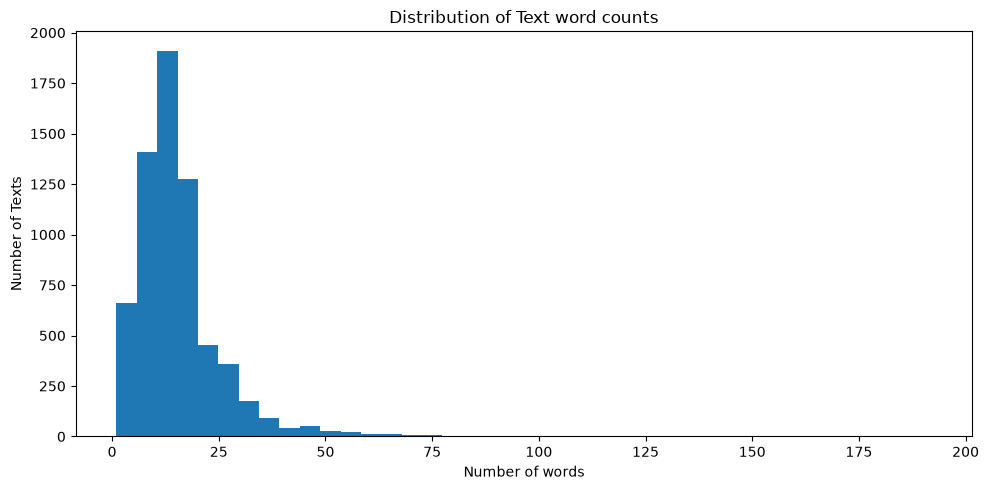

In [25]:
import matplotlib.pyplot as plt

#Character count distribution
plt.figure(figsize=(10,5))
plt.hist(df_audit["word_count"], bins=40)
plt.title("Distribution of Text word counts")
plt.xlabel("Number of words")
plt.ylabel("Number of Texts")
plt.tight_layout()
plt.show()

In [26]:
#Inspect the long entries 
longest_texts = (
    df_audit.nlargest(10, "word_count")[["Text", "Label", "word_count"]]
)
for _, row in longest_texts.iterrows():
    print(f"\nLabel: {row['Label']} | Words: {row['word_count']}")
    print(row["Text"][:500])  # Print the first 500 characters of the text
    
    print("-" * 80)


Label: 2 | Words: 192
Huyu ni mcheshi mwingine tu anayetoa madai yasiyo na msingi. Analalamika Wakenya wanalipwa kodi nyingi kisha anasema anataka huduma za afya za bure kwa wote. Hakuna chakula cha bure katika uchumiikiwa unataka huduma za afya za bure kwa kila mtu, kodi lazima ziongezeke, sio kupungua. Unapojilinganisha na viwango vya kodi duniani, yetu ni ya chini hadi ya kati. Canada ni nchi tajiri kwa mafuta yenye watu milioni 41 tu, ikipata $150 bilioni kila mwaka kutoka mauzo ya mafuta, inayotosha kufadhili v
--------------------------------------------------------------------------------

Label: 0 | Words: 183
Inspekta Jenerali wa Huduma ya Polisi wa Taifa (NPS), Bw. Douglas Kanja, leo ameongoza maafisa wakuu wa polisi na jamii pana ya polisi kwenye mazishi ya Agnes Mugure Mburu nyumbani kwake Kabati, Kaunti ya Muranga. Alikuwa mke mpendwa wa Naibu Kamanda wa Kitengo cha Huduma ya Jumla (GSU), Bw. Godhard Kamau, AIG. Wakati wa ibada ya hisia, alikumbukwa kwa upendo kwa kujit

In [27]:
# Inspect unusual Characters 

import re 
patterns ={
    "Replacement character": "\uFFFD",
    "Null character": "\x00",
    "Curly quotation marks": "[\"'\"\'\']",
    "Ellipis character": "\u2026",
    "HTML entities": r"&(?:amp|lt|gt|quot|apos|nbsp);"

}

for name, pattern in patterns.items():
    count = df["Text"].str.contains(
        pattern,
        regex=True,
        na=False
    ).sum()
    print(f"{name}: {count} texts containing this pattern")

Replacement character: 0 texts containing this pattern
Null character: 0 texts containing this pattern
Curly quotation marks: 200 texts containing this pattern
Ellipis character: 0 texts containing this pattern
HTML entities: 0 texts containing this pattern


In [28]:
#inspect text lengths and labels without priniting full paragraphs 
print(
    df_audit.nlargest(10, "word_count")[
        ["Label", "word_count", "character_count"]
    ].to_string(index=False)
)

Label  word_count  character_count
    2         192             1236
    0         183             1107
    0         183             1107
    2         182             1254
    0         173             1141
    2         145              921
    0         135              872
    0         130              831
    0         117              706
    0         103              684


Label counts:
Label
0                4316
1                1590
2                 630
0  / Humorous       1
0  / 1              1
Name: count, dtype: int64

Label percentages:
Label
0                66.01
1                24.32
2                 9.64
0  / Humorous     0.02
0  / 1            0.02
Name: proportion, dtype: float64


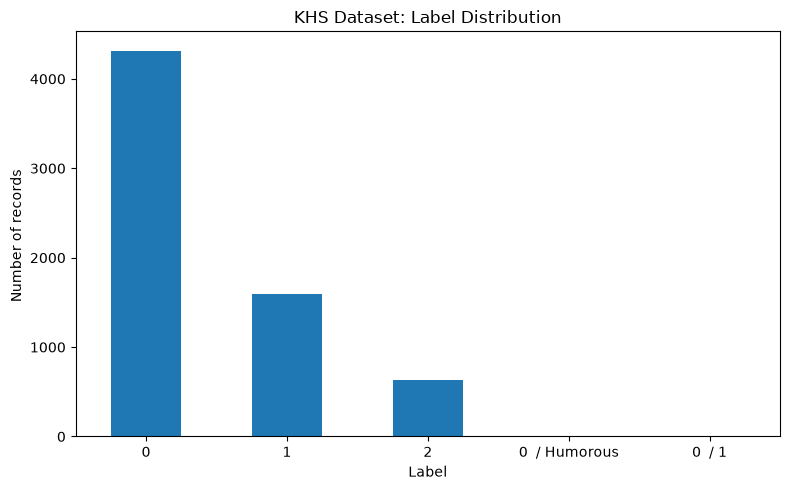

In [29]:
#label distribution 

import matplotlib.pyplot as plt 

label_counts =df["Label"].value_counts()
print("Label counts:")
print(label_counts)

print("\nLabel percentages:")
print((df["Label"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(8, 5))
label_counts.plot(kind='bar')
plt.title("KHS Dataset: Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of records ")
plt.xticks(rotation= 0)
plt.tight_layout()
plt.show()


In [30]:
# Create a safe working copy

import pandas as pd
from pathlib import Path

# Preserve the original df and create a separate working copy
df_work = df.copy()

# Standardise surrounding whitespace in text and labels
df_work["Text"] = df_work["Text"].astype(str).str.strip()
df_work["Label"] = df_work["Label"].astype(str).str.strip()

# Save records with labels outside the three main classes for review
valid_labels = ["0", "1", "2"]

unusual_records = df_work[
~df_work["Label"].isin(valid_labels)
].copy()

# Identify all rows whose text has conflicting labels
labels_per_text = df_work.groupby("Text")["Label"].nunique()
conflict_texts = labels_per_text[labels_per_text > 1].index

conflict_records = df_work[
df_work["Text"].isin(conflict_texts)
].copy()

print("Original rows:", len(df))
print("Working-copy rows:", len(df_work))
print("Unusual-label records:", len(unusual_records))
print("Rows in conflicting text groups:", len(conflict_records))
print("Original df unchanged:", len(df) == len(df_work))


Original rows: 6538
Working-copy rows: 6538
Unusual-label records: 2
Rows in conflicting text groups: 23
Original df unchanged: True


In [31]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

unusual_records.to_csv(
output_dir / "khs_unusual_labels_for_review.csv",
index=False
)

conflict_records.to_csv(
output_dir / "khs_conflicting_labels_for_review.csv",
index=False
)

print("Review files saved to:", output_dir.resolve())

Review files saved to: C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed


In [32]:
# Create a preliminary modelling candidate

from pathlib import Path

df_work = df.copy()

# Normalize surrounding whitespace
df_work["Text"] = df_work["Text"].astype(str).str.strip()
df_work["Label"] = df_work["Label"].astype(str).str.strip()

# Identify valid labels
valid_labels = ["0", "1", "2"]
valid_label_mask = df_work["Label"].isin(valid_labels)

# Identify texts associated with multiple labels
labels_per_text = df_work.groupby("Text")["Label"].nunique()
conflict_texts = labels_per_text[labels_per_text > 1].index

# Exclude unusual labels and conflicting text groups
df_candidate = df_work[
valid_label_mask &
~df_work["Text"].isin(conflict_texts)
].copy()

rows_before_deduplication = len(df_candidate)

# Remove duplicate text-label pairs
df_candidate = df_candidate.drop_duplicates(
subset=["Text", "Label"],
keep="first"
).copy()

print("Original rows:", len(df))
print("Rows before deduplication:", rows_before_deduplication)
print("Rows after deduplication:", len(df_candidate))
print("\nLabel distribution:")
print(df_candidate["Label"].value_counts())

# Save the candidate separately
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "khs_preliminary_clean.csv"
df_candidate.to_csv(output_path, index=False)

print("\nSaved to:", output_path.resolve())


Original rows: 6538
Rows before deduplication: 6513
Rows after deduplication: 6328

Label distribution:
Label
0    4167
1    1532
2     629
Name: count, dtype: int64

Saved to: C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed\khs_preliminary_clean.csv


### Exploratory Data analysis (NLP)

In [33]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load preliminary cleaned dataset
df_clean = pd.read_csv(
    "khs_preliminary_clean.csv",
    dtype={"Label": str}
)

print("Dataset shape:", df_clean.shape)
print("\nColumns:", df_clean.columns.tolist())
print("\nFirst five records:")
display(df_clean.head())


Dataset shape: (6328, 2)

Columns: ['Text', 'Label']

First five records:


,Text,Label
0,Haja ya kuona watoto wa baba mbele mgomo ahadi...,2
1,tafadhali katiba ya ruto iruhusu maandamano ya...,2
2,hakika ardhi linganisha sifuna malala,2
3,kinyume cha sheria silly linganisha malala sif...,2
4,hornbill inayofanya kelele kila siku inayoitwa...,2


Text length statistics:


,character_count,word_count
count,6328.000000,6328.000000
mean,101.399652,15.477876
std,74.158763,11.243282
min,4.000000,1.000000
25%,60.000000,9.000000
50%,87.000000,13.000000
75%,121.000000,19.000000
max,1254.000000,192.000000


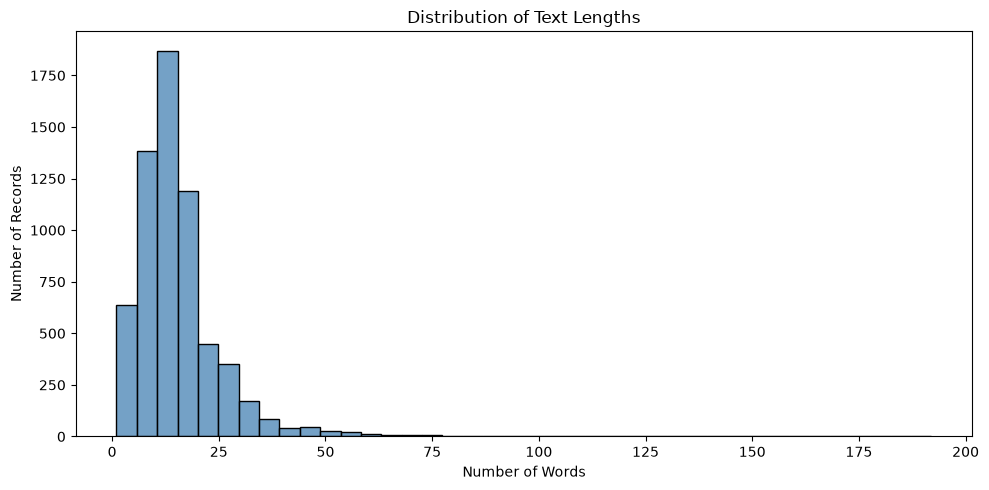

In [34]:
# Analyze length texts 

# Calculate text lengths
df_clean["character_count"] = df_clean["Text"].str.len()

df_clean["word_count"] = (
    df_clean["Text"].str.split().str.len()
)

# Summary statistics
print("Text length statistics:")
display(
    df_clean[
        ["character_count", "word_count"]
    ].describe()
)

# Visualize word count distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="word_count",
    bins=40,
    color="steelblue"
)

plt.title("Distribution of Text Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


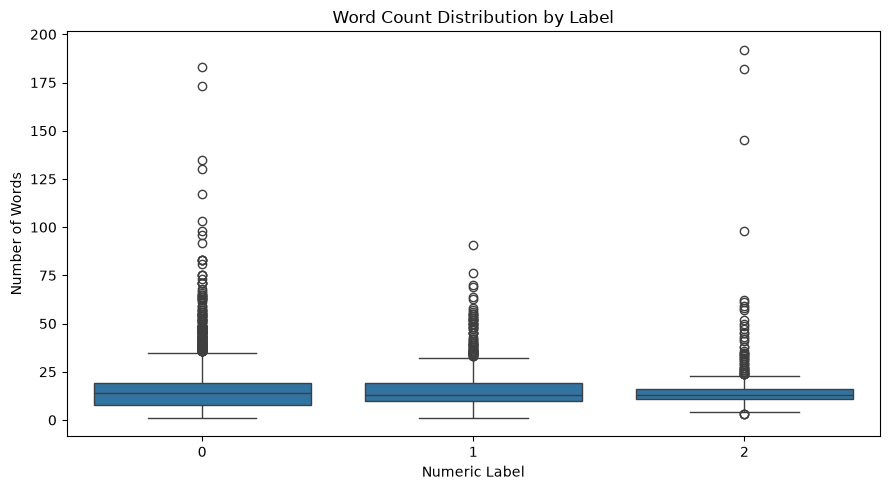

,count,mean,median,min,max
Label,,,,,
0,4167,15.50,14.0,1,183
1,1532,15.45,13.0,1,91
2,629,15.42,13.0,3,192


In [35]:
# Compare the tet lengths across different labels 

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="Label",
    y="word_count",
    order=["0", "1", "2"]
)

plt.title("Word Count Distribution by Label")
plt.xlabel("Numeric Label")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

# Summary by label
display(
    df_clean.groupby("Label")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)


### Word Count Distribution by Label: Outlier Analysis


- **Label 0:** Has the most outliers. There is a dense cluster between about 35 and 75 words, with a few extreme values reaching roughly 183 words. This is probably because Label 0 is the largest class, so it has more chances to contain long texts.
- **Label 1:** Shows a similar pattern, with outliers mostly below about 90 words and fewer extreme values.
- **Label 2:** Has the tightest spread (about 11–16 words) and the fewest outliers. However, a handful of values (about 145, 182 and 192 words) sit far above the rest and should be inspected.

 **Conclusion** Text length is an important characteristic to document during preprocessing. Long texts should be investigated, and any token-length limits used in future NLP models should be justified.

### Checking for which words appear most in the dataset

In [36]:

from collections import Counter
import re
import pandas as pd
import matplotlib.pyplot as plt

# Combine all text and convert to lowercase
all_text = " ".join(
    df_clean["Text"].dropna().astype(str)
).lower()

# Extract word-like tokens
tokens = re.findall(r"\b\w+\b", all_text, flags=re.UNICODE)

# Count word frequencies
word_counts = Counter(tokens)

# Display the 25 most frequent words
top_words = pd.DataFrame(
    word_counts.most_common(25),
    columns=["Word", "Frequency"]
)

display(top_words)


,Word,Frequency
0,ya,3168
1,na,2964
2,wa,2387
3,kwa,2316
4,ni,1237
5,baba,773
6,za,747
7,kenya,701
8,sana,698
9,bila,619


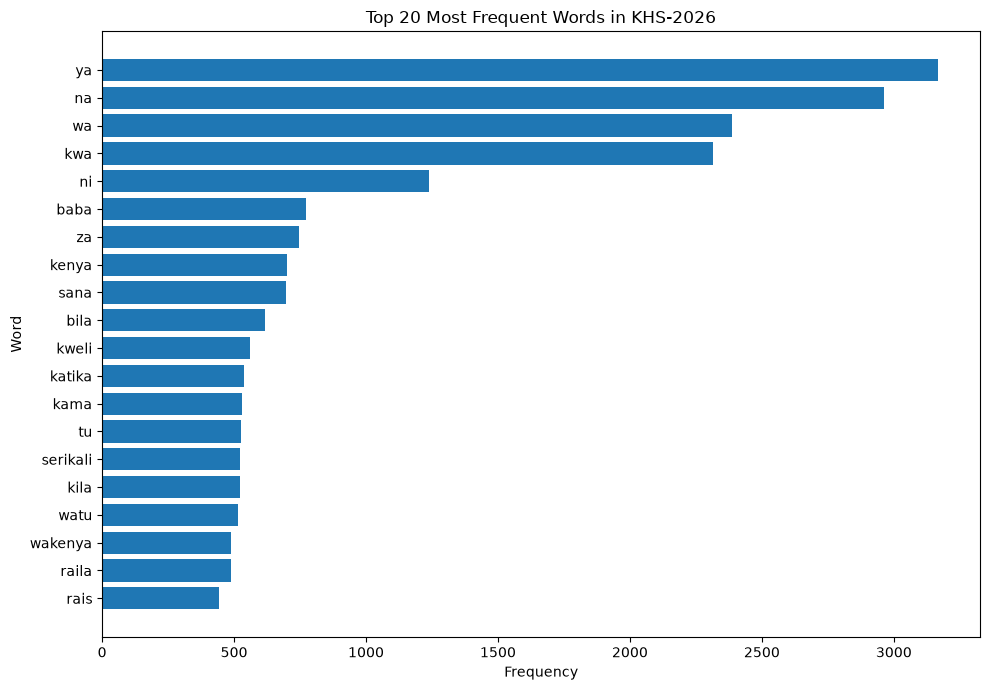

In [37]:
#Visualize the top 20 words 

top_20 = top_words.head(20).sort_values(
    "Frequency",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_20["Word"],
    top_20["Frequency"]
)

plt.title("Top 20 Most Frequent Words in KHS-2026")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


### Interpratation of the most used words 

#### 1. Most common words are social words as compared to political words 
#### 2.There are many common Kiswahili words that appear in the sentences like wa, ya , na
#### 3.Words like wa, ya , na appear frequently but provide little meaningful information 

### Word Frequency Analysis — Findings

##### The 25 most frequent tokens were extracted from the preliminary cleaned KHS-2026 dataset after converting the text to lowercase.

##### The most frequent token was **ya**, appearing **3168** times.

##### The frequency analysis helps identify common vocabulary, potential stopwords, and terms that may be useful for understanding the dataset's linguistic characteristics.

##### At this stage, no words have been removed from the dataset. Stopword removal, normalization, and other preprocessing decisions will be evaluated carefully because common words and linguistic context can be important for hate-speech detection.

##### Conclusion: Word frequency analysis provides an initial understanding of the vocabulary and informs subsequent NLP preprocessing decisions.

In [38]:
# Compare the top 15 words across each numeric label 

from collections import Counter
import re
import pandas as pd

for label in ["0", "1", "2"]:
    label_text = " ".join(
        df_clean.loc[
            df_clean["Label"].astype(str) == label,
            "Text"
        ].dropna().astype(str)
    ).lower()

    tokens = re.findall(
        r"\b\w+\b",
        label_text,
        flags=re.UNICODE
    )

    frequencies = Counter(tokens)

    print(f"\nTop 15 words for numeric label {label}:")

    display(pd.DataFrame(
        frequencies.most_common(15),
        columns=["Word", "Frequency"]
    ))



Top 15 words for numeric label 0:


,Word,Frequency
0,ya,2214
1,na,1987
2,kwa,1636
3,wa,1593
4,ni,731
5,baba,543
6,za,494
7,sana,484
8,kenya,479
9,bila,424



Top 15 words for numeric label 1:


,Word,Frequency
0,ya,720
1,na,679
2,wa,559
3,kwa,455
4,ni,284
5,za,190
6,bila,159
7,watu,157
8,baba,153
9,serikali,153



Top 15 words for numeric label 2:


,Word,Frequency
0,na,298
1,wa,235
2,ya,234
3,kwa,225
4,ni,222
5,tu,109
6,baba,77
7,sana,73
8,ushuru,73
9,kenya,70


In [39]:
# Calculate normalized word frequencies 

from collections import Counter
import re
import pandas as pd

label_frequency_tables = []

for label in ["0", "1", "2"]:
    label_text = " ".join(
        df_clean.loc[
            df_clean["Label"].astype(str) == label,
            "Text"
        ].dropna().astype(str)
    ).lower()

    tokens = re.findall(
        r"\b\w+\b",
        label_text,
        flags=re.UNICODE
    )

    counts = Counter(tokens)
    total_tokens = len(tokens)

    for word, count in counts.items():
        label_frequency_tables.append({
            "Label": label,
            "Word": word,
            "Count": count,
            "Total_Tokens": total_tokens,
            "Frequency_Per_1000_Tokens":
                (count / total_tokens) * 1000
        })

normalized_freq = pd.DataFrame(label_frequency_tables)

# Inspect selected words across the three labels
words_to_compare = [
    "serikali", "kenya", "raila",
    "watu", "ushuru", "polisi",
    "baba", "sana"
]

comparison = normalized_freq[
    normalized_freq["Word"].isin(words_to_compare)
].pivot(
    index="Word",
    columns="Label",
    values="Frequency_Per_1000_Tokens"
).fillna(0)

comparison.columns = [
    f"Label_{label}" for label in comparison.columns
]

display(comparison.round(2))


,Label_0,Label_1,Label_2
Word,,,
baba,8.37,6.45,7.87
kenya,7.39,6.40,7.15
polisi,3.64,4.84,4.09
raila,4.69,5.90,4.39
sana,7.46,5.94,7.46
serikali,4.63,6.45,7.15
ushuru,1.76,1.56,7.46
watu,4.60,6.61,6.13


###  Normalized Word Frequency Analysis

Word frequencies were normalized to occurrences per 1,000 tokens to account for differences in the total text volume across numeric label groups.

The most notable observed difference was for **ushuru** , which occurred at 1.76, 1.56, and 7.46 occurrences per 1,000 tokens in labels 0, 1, and 2, respectively. The normalized frequency of **serikali** also increased across these groups, while **polisi** and **raila** showed relatively higher frequencies in label 1.

These observations identify candidate terms for further investigation. They do not establish that the terms are associated with hate speech, and their interpretation depends on the verified label mapping and sentence context.

**Conclusion:** Normalized word frequencies reveal differences in vocabulary use that warrant further analysis using TF-IDF and context-aware NLP methods.

### Create TF-IDF matrix


In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer 
import pandas as pd 

# Keep the cleaned text as strings
texts = df_clean["Text"].fillna("").astype(str)

#Create TF-IDF features 
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2,
)

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("Number of documents:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print("Matrix sparsity:", 
      round(100 * (1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])), 2), "%")

Number of documents: 6328
Number of features: 3000
Matrix sparsity: 99.53 %


In [41]:
#Inspect the highest scoring TF-IDF Features 
feature_names = tfidf_vectorizer.get_feature_names_out()
feature_weights = tfidf_matrix.mean(axis=0).A1

tfidf_summary = pd.DataFrame({
    "Feature": feature_names,
    "Average_TF-IDF_Weight": feature_weights
}).sort_values(by="Average_TF-IDF_Weight", ascending=False) 
display(tfidf_summary.head(25).round(4))

,Feature,Average_TF-IDF_Weight
2802,ya,0.0426
1699,na,0.0391
2522,wa,0.0355
1152,kwa,0.0340
1851,ni,0.0227
163,baba,0.0205
2077,sana,0.0169
2948,za,0.0162
783,kenya,0.0161
2248,tu,0.0151


#### TF-IDF Feature Analysis

##### The resulting document-term matrix contains 6,328 documents and 3,000 features, with a sparsity of 99.53%. This indicates that most documents contain only a small subset of the vocabulary represented in the feature space.

##### The highest average TF-IDF weights included common Kiswahili terms such as ya, na, wa, and kwa, as well as terms associated with Kenyan political and social discussion, including Kenya, serikali, polisi, and maandamano.


Conclusion: TF-IDF successfully transformed the text into a sparse numerical representation suitable for later classification experiments.

In [42]:
# Comparing of TF-IDF weights seperately for each label
import numpy as np
import pandas as pd 

feature_names = tfidf_vectorizer.get_feature_names_out()

for label in ["0", "1", "2"]:
    #Find documents corresponding to the current label
    mask = df_clean["Label"].astype(str).eq(label).to_numpy()

    # Calculate mean TF-IDF weights for each feature within the current label
    mean_weights = np.asarray(tfidf_matrix[mask].mean(axis=0)).ravel()

    # Get the 15 highest weight features for the current label
    top_indices = np.argsort(mean_weights)[::-1][:15]

    label_tfidf_summary = pd.DataFrame({
        "Feature": feature_names[top_indices],
        "Average_TF-IDF_Weight": mean_weights[top_indices]
    })
    print(f"\nTop 15 TF-IDF Features for Label {label}:")
    display(label_tfidf_summary.round(4))


Top 15 TF-IDF Features for Label 0:


,Feature,Average_TF-IDF_Weight
0,ya,0.0449
1,na,0.0388
2,kwa,0.0359
3,wa,0.0357
4,baba,0.0215
5,ni,0.0197
6,sana,0.0177
7,kenya,0.0163
8,za,0.0160
9,kweli,0.0152



Top 15 TF-IDF Features for Label 1:


,Feature,Average_TF-IDF_Weight
0,ya,0.0406
1,na,0.0392
2,wa,0.0351
3,kwa,0.0284
4,ni,0.0225
5,za,0.0178
6,baba,0.0177
7,watu,0.0176
8,polisi,0.0165
9,tu,0.0162



Top 15 TF-IDF Features for Label 2:


,Feature,Average_TF-IDF_Weight
0,ni,0.0436
1,na,0.0411
2,wa,0.0357
3,kwa,0.0351
4,ya,0.0325
5,tu,0.0300
6,ushuru,0.0254
7,baba,0.0211
8,wacha,0.0207
9,kweli,0.0202


In [43]:
# Inspecting URLs, hashtags, mentions and emojis 

import re 
import pandas as pd 

text_series = df_clean["Text"].fillna("").astype(str)
text_feature_audit = pd.Series({
    "Total documents": len(text_series),
    "Documents with URLs": text_series.str.contains(r"http?://|www\.", case = False, regex=True).sum(),
    "Documents with Hashtags": text_series.str.contains(r"#\w+", regex=True).sum(),
    "Documents with Mentions": text_series.str.contains(r"@\w+", regex=True).sum(),
    "Documents with digits": text_series.str.contains(r"\d", regex=True).sum(),
    "Documents with Emojis": text_series.str.contains(r"[^\w\s]", regex=True).sum(),
    "Documents with line breaks": text_series.str.contains(r"[\r\n]", regex=True).sum(), 
       
})

display(text_feature_audit.to_frame(name="Count"))

,Count
Total documents,6328
Documents with URLs,0
Documents with Hashtags,16
Documents with Mentions,9
Documents with digits,304
Documents with Emojis,3661
Documents with line breaks,0


###  Text Feature Audit — Findings

The preliminary cleaned dataset contains 6,328 documents. No URLs or line breaks were detected using the selected patterns. Hashtags were detected in 16 documents, mentions in 9 documents, and digits in 304 documents.

A broad non-word-symbol check flagged 3,661 documents. This count includes punctuation and other symbols and must not be interpreted as an exact emoji count.

The original text will be preserved while preprocessing decisions are evaluated. Digits, hashtags, mentions, emojis, and punctuation will not be removed automatically because they may carry useful linguistic or contextual information.

**Conclusion:** The audit provides an initial overview of text features that may influence NLP preprocessing. More targeted inspection is needed before applying any destructive text transformations.

In [44]:

# Inspect texts containing hashtags
print("Examples containing hashtags:")
display(
    df_clean.loc[
        df_clean["Text"].str.contains(r"#\w+", regex=True, na=False),
        ["Text", "Label"]
    ].head(5)
)

# Inspect texts containing mentions
print("\nExamples containing mentions:")
display(
    df_clean.loc[
        df_clean["Text"].str.contains(r"@\w+", regex=True, na=False),
        ["Text", "Label"]
    ].head(5)
)

# Inspect texts containing digits
print("\nExamples containing digits:")
display(
    df_clean.loc[
        df_clean["Text"].str.contains(r"\d", regex=True, na=False),
        ["Text", "Label"]
    ].head(5)
)

# Inspect texts containing non-word symbols
print("\nExamples containing non-word symbols:")
display(
    df_clean.loc[
        df_clean["Text"].str.contains(r"[^\w\s]", regex=True, na=False),
        ["Text", "Label"]
    ].head(10)
)


Examples containing hashtags:


,Text,Label
3601,"Dunia ni ya ajabu, wanatafuta dola, #downWithD...",2
3726,Kwa mtazamo wa nyuma ni neno ambalo mara nying...,0
3891,Haki za katiba lazima zitekelezwe mara moja na...,0
3975,Jenerali mzuri anajua wakati wa kuwa mitini na...,0
4044,"Bosi anazungumza akili, kama kawaida #TheKenya...",0



Examples containing mentions:


,Text,Label
4342,Hotuba nzuri sana @Raila Amolo yenye maana kub...,0
5358,@diaryofaceo tafadhali mlete Dk. Gabor Maté ep...,0
5560,"Pamoja na wenzangu wa Baraza la Mawaziri, Davi...",0
5582,Watu wanaanza kuona upuuzi tunaopitia huku Sif...,0
6024,"@SeniorCounselPaulMwangi, hiyo ilikuwa maelezo...",0



Examples containing digits:


,Text,Label
86,jua arrrrm watu w2ver even means hawezi kwenda...,2
976,baba western bedroom kindly w2ver wish taifa l...,0
1237,leo wakenya waaminifu walijua neno kwenda kuon...,0
1374,jua arrrrm watu w2ver even means hawezi kwenda...,0
1521,"""Tutatuma wajumbe wa kamati teule ya kumbukumb...",0



Examples containing non-word symbols:


,Text,Label
16,polisi kikatili kuangalia kwa makini kalenjins...,2
17,"Kijana lazima akamatwe sana, hawa watu wa kund...",2
18,"wanataka kuonyesha haki za heshima tu, hawa wa...",2
19,Afisa wa polisi alihusisha sare za operesheni ...,2
20,vijana wengi wasio na hatia tayari wamepoteza ...,2
21,"Kwa maoni yangu, wiki ijayo hawezi kukwepa wak...",2
22,unataka kuwa rais wa nchi tafadhali jifunze ku...,2
23,"hiyo ni serikali kutambua kushughulika, kwa kw...",2
24,"Kwa maoni yangu, uhalifu wa polisi uliofanywa ...",2
25,"Kwa maoni yangu, wakenya tukiunga mkono hakuna...",2


In [45]:
#Checking for unusual character encoding
import pandas as pd

text_series = df_clean["Text"].fillna("").astype(str)

encoding_checks = {
    "Replacement character (�)": "\uFFFD",
    "Null character": "\x00",
    "Unicode replacement marker": "\uFFFD",
    "Common mojibake character (Ã)": "Ã",
    "Common mojibake character (Â)": "Â",
    "Curly opening quotation mark": "“",
    "Curly closing quotation mark": "”",
    "Curly apostrophe": "’",
}

encoding_results = []

for description, character in encoding_checks.items():
    matching = text_series.str.contains(
        character, regex=False, na=False
    )

    encoding_results.append({
        "Character check": description,
        "Documents affected": int(matching.sum())
    })

display(pd.DataFrame(encoding_results))


,Character check,Documents affected
0,Replacement character (�),0
1,Null character,0
2,Unicode replacement marker,0
3,Common mojibake character (Ã),10
4,Common mojibake character (Â),0
5,Curly opening quotation mark,0
6,Curly closing quotation mark,0
7,Curly apostrophe,0


In [46]:
# Inspect the 10 records 

# Find records containing the suspicious character Ã

suspicious_mask = df_clean["Text"].str.contains(
    "Ã",
    regex=False,
    na=False
)

suspicious_records = df_clean.loc[
    suspicious_mask, ["Text", "Label"]
].copy()

print("Number of suspicious records:", len(suspicious_records))

display(suspicious_records)


Number of suspicious records: 10


,Text,Label
55,"Kwa maoni yangu, mkundu alisema ""ikijulikana v...",2
142,mzee aliwezesha biashara za kuvuruga uporaji m...,2
249,mzee aliwezesha biashara za kuvuruga uporaji m...,0
477,nimeenda ndoa shida shida riggy g problemÃ©,0
1017,gÃ chagua finish aliar pole raila kisiasa,0
1350,inakumbusha miaka iliyopita mtu alijaribu kitu...,0
1581,ufadhili hufanya hisia apperanÃ§e kimwili,0
1683,acha ruto afanye kazi Ãºa kazi chama cha upinz...,0
2210,inakumbusha miaka iliyopita mtu alijaribu kitu...,0
2558,"mkundu alisema ""ikijulikana vÃ¤ginÃ wageni we...",1


In [47]:

# Display suspicious records in full, without truncation

pd.set_option("display.max_colwidth", None)

display(
    df_clean.loc[
        df_clean["Text"].str.contains("Ã", regex=False, na=False),
        ["Text", "Label"]
    ].to_string(index=True)
)

# Check duplicate text groups among flagged records
flagged = df_clean[
    df_clean["Text"].str.contains("Ã", regex=False, na=False)
].copy()

print("\nRepeated text among flagged records:")
display(
    flagged[flagged["Text"].duplicated(keep=False)]
    .sort_values("Text")
)


'                                                                                                                                                 Text Label\n55                                                      Kwa maoni yangu, mkundu alisema "ikijulikana vÃ¤ginÃ\xa0 wageni wengi hawatakubali kamwe jirani"     2\n142   mzee aliwezesha biashara za kuvuruga uporaji mÃ¬nyonyoto sisi wapenda amani kenyansthat guy hero encourage kufanya vizuri zaidi wakati ujao. tu     2\n249      mzee aliwezesha biashara za kuvuruga uporaji mÃ¬nyonyoto sisi wapenda amani kenyansthat guy hero encourage kufanya vizuri zaidi wakati ujao.     0\n477                                                                                                       nimeenda ndoa shida shida riggy g problemÃ©     0\n1017                                                                                                        gÃ\xa0chagua finish aliar pole raila kisiasa     0\n1350                 inakumbusha miaka iliyopita mt


Repeated text among flagged records:


,Text,Label,character_count,word_count


In [48]:

# Checking for any duplicate texts and conflicting labels for the cleaned dataset

print("Total rows:", len(df_clean))

# Exact duplicate text-label rows
print(
    "Exact duplicate rows:",
    df_clean.duplicated(subset=["Text", "Label"]).sum()
)

# Texts appearing more than once
print(
    "Repeated text rows:",
    df_clean["Text"].duplicated(keep=False).sum()
)

# Texts assigned more than one label
labels_per_text = df_clean.groupby("Text")["Label"].nunique()
remaining_conflicts = labels_per_text[labels_per_text > 1]

print(
    "Text groups with conflicting labels:",
    len(remaining_conflicts)
)

if len(remaining_conflicts) > 0:
    conflict_examples = df_clean[
        df_clean["Text"].isin(remaining_conflicts.index)
    ].sort_values("Text")

    display(conflict_examples[["Text", "Label"]])
else:
    print("No conflicting-label text groups remain.")


Total rows: 6328
Exact duplicate rows: 0
Repeated text rows: 0
Text groups with conflicting labels: 0
No conflicting-label text groups remain.


In [49]:

# Consolidated dataset audit

import pandas as pd

original_rows = len(df)
clean_rows = len(df_clean)

print("DATASET CLEANING SUMMARY")
print("-" * 35)
print("Original dataset:", original_rows)
print("Preliminary clean dataset:", clean_rows)
print("Rows removed:", original_rows - clean_rows)
print("Percentage retained:", round(clean_rows / original_rows * 100, 2), "%")

print("\nLabel distribution:")
label_summary = pd.DataFrame({
    "Count": df_clean["Label"].value_counts(),
    "Percentage": (
        df_clean["Label"].value_counts(normalize=True) * 100
    ).round(2)
})

display(label_summary)

print("\nRemaining duplicate text-label rows:",
      df_clean.duplicated(subset=["Text", "Label"]).sum())

print("Remaining conflicting text groups:",
      (df_clean.groupby("Text")["Label"].nunique() > 1).sum())


DATASET CLEANING SUMMARY
-----------------------------------
Original dataset: 6538
Preliminary clean dataset: 6328
Rows removed: 210
Percentage retained: 96.79 %

Label distribution:


,Count,Percentage
Label,,
0,4167,65.85
1,1532,24.21
2,629,9.94



Remaining duplicate text-label rows: 0
Remaining conflicting text groups: 0


# KHS-2026 Dataset — Preliminary Cleaning Report

### 1. Dataset Overview
The original CSV contained 6,538 records and two columns: `Text` and `Label`.

### 2. Cleaning Results
A preliminary clean dataset containing 6,328 records was created. Unusual label values and conflicting-label text groups were excluded from this candidate, and duplicate text-label pairs were removed. The original dataset was preserved.

### 3. Consistency Checks
The preliminary clean dataset contains no exact duplicate text-label rows, repeated texts, or conflicting-label text groups according to the checks performed.

### 4. Text Quality
Text-length analysis, word-frequency analysis, normalized word frequencies, TF-IDF exploration, and checks for URLs, hashtags, mentions, digits, symbols, and suspicious encoding characters were conducted. Ten records containing `Ã` were flagged for manual review rather than automatically corrected.

### 5. Class Distribution
The dataset retains three numeric labels. Their distribution is documented in the notebook output. The official mapping between numeric values and semantic categories has not yet been verified.

### 6. Outstanding Issues
- Confirm the numeric label mapping with the dataset authors.
- Investigate suspicious encoding sequences.
- Clarify the difference between the downloaded CSV's 6,538 records and the 6,451 records described as the cleaned release.
- Review the final preprocessing strategy before supervised model training.



### Modelling:Train/Test split

In [50]:

from sklearn.model_selection import train_test_split

# Input text and numeric target labels
X = df_clean["Text"].astype(str)
y = df_clean["Label"].astype(str)

# Reserve 20% for final testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))


Training records: 5062
Testing records: 1266

Training label distribution:
Label
0    65.84
1    24.22
2     9.94
Name: proportion, dtype: float64

Testing label distribution:
Label
0    65.88
1    24.17
2     9.95
Name: proportion, dtype: float64


#### Preliminary Modelling Protocol

The preliminary clean dataset will use an 80:20 stratified train/test split with a fixed random seed of 42. 
The training data will be used for feature extraction, model fitting, and model selection. The test data will be reserved for final evaluation.

TF-IDF vectorization must be fitted on the training data only and then applied to validation and test data using the fitted vectorizer. This prevents vocabulary and document-frequency information from leaking from the evaluation data.

The baseline evaluation will report precision, recall, F1-score, and a confusion matrix for each numeric class, alongside overall accuracy and macro-F1.

The official numeric label mapping must be verified before assigning semantic class names or drawing conclusions about hate-speech detection performance.

In [51]:

# Check for exact text overlap between training and testing sets

train_texts = set(X_train)
test_texts = set(X_test)

overlapping_texts = train_texts.intersection(test_texts)

print("Unique training texts:", len(train_texts))
print("Unique testing texts:", len(test_texts))
print("Exact texts appearing in both sets:", len(overlapping_texts))

if len(overlapping_texts) == 0:
    print("PASS: No exact text overlap detected.")
else:
    print("WARNING: Investigate overlapping texts before modelling.")


Unique training texts: 5062
Unique testing texts: 1266
Exact texts appearing in both sets: 0
PASS: No exact text overlap detected.


In [52]:
#Create a pipeline
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

baseline_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            max_features=3000,
            ngram_range=(1, 2),
            min_df=2
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("Baseline pipeline created successfully.")
print(baseline_pipeline)


Baseline pipeline created successfully.
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=3000, min_df=2,
                                 ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


### Saving the split files 

In [53]:

from pathlib import Path
import pandas as pd

# Create an output folder
output_dir = Path("../data/processed/model_splits")
output_dir.mkdir(parents=True, exist_ok=True)

# Save training data
train_df = pd.DataFrame({
    "Text": X_train,
    "Label": y_train
})
train_df.to_csv(
    output_dir / "khs_train.csv",
    index=False
)

# Save testing data
test_df = pd.DataFrame({
    "Text": X_test,
    "Label": y_test
})
test_df.to_csv(
    output_dir / "khs_test.csv",
    index=False
)

print("Training file saved:", (output_dir / "khs_train.csv").resolve())
print("Testing file saved:", (output_dir / "khs_test.csv").resolve())
print("Training records:", len(train_df))
print("Testing records:", len(test_df))


Training file saved: C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed\model_splits\khs_train.csv
Testing file saved: C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed\model_splits\khs_test.csv
Training records: 5062
Testing records: 1266


In [54]:
# Train the baseline classifier

# Fit TF-IDF and Logistic Regression using training data only
baseline_pipeline.fit(X_train, y_train)

print("Baseline model training completed.")

# Generate predictions on the reserved test set
y_pred = baseline_pipeline.predict(X_test)

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())


Baseline model training completed.

First 10 actual labels:
['0', '1', '2', '0', '1', '1', '0', '0', '0', '0']

First 10 predicted labels:
['1', '0', '1', '0', '1', '1', '0', '0', '1', '0']


In [55]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# Evaluate the baseline model
def evaluate_classifier(model, X_test, y_test):
    predictions = model.predict(X_test)

    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Macro-F1:", round(f1_score(y_test, predictions, average="macro"), 4))
    print("\nClassification report:")
    print(classification_report(y_test, predictions, labels=["0", "1", "2"], zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions, labels=["0", "1", "2"]))

    return predictions


y_pred = evaluate_classifier(
    baseline_pipeline,
    X_test,
    y_test
)


Accuracy: 0.5979
Macro-F1: 0.4974

Classification report:
              precision    recall  f1-score   support

           0       0.79      0.67      0.72       834
           1       0.39      0.48      0.43       306
           2       0.29      0.41      0.34       126

    accuracy                           0.60      1266
   macro avg       0.49      0.52      0.50      1266
weighted avg       0.64      0.60      0.61      1266

Confusion matrix:
[[559 192  83]
 [115 146  45]
 [ 36  38  52]]


###  Baseline Model Explanation

A baseline Logistic Regression classifier using TF-IDF features was trained on 5,062 records and evaluated on 1,266 held-out records.

The model achieved an accuracy of 59.79% and a macro-F1 score of 0.4974.

The per-class F1-scores were:
- Label 0: 0.72
- Label 1: 0.43
- Label 2: 0.34

The results indicate uneven performance across the three numeric classes. Label 0 was predicted most effectively, while label 2 had the lowest F1-score.

The confusion matrix showed substantial misclassification between labels 0 and 1, as well as missed examples of label 2.

These results establish an initial benchmark. The numeric label mapping remains unverified, so the findings describe prediction of dataset labels rather than confirmed hate-speech detection performance.

### Inspecting the label meanings before creating a subset

In [56]:

print("Available labels:")
print(df_clean["Label"].value_counts().sort_index())

print("\nNumber of records selected for annotation:")

for label in ["0", "1", "2"]:
    count = (df_clean["Label"].astype(str) == label).sum()
    print(f"Label {label}: {count} available records")


Available labels:
Label
0    4167
1    1532
2     629
Name: count, dtype: int64

Number of records selected for annotation:
Label 0: 4167 available records
Label 1: 1532 available records
Label 2: 629 available records


In [57]:
# Creating the annonation sample

from pathlib import Path
import pandas as pd

review_dir = Path("../data/processed/label_review")
review_dir.mkdir(parents=True, exist_ok=True)

source = df_clean[["Text", "Label"]].copy()
source["Label"] = source["Label"].astype(str)

samples = []

for label in ["0", "1", "2"]:
    group = source[source["Label"] == label]

    sample = group.sample(
        n=min(30, len(group)),
        random_state=42
    ).copy()

    samples.append(sample)

review_sample = pd.concat(
    samples,
    ignore_index=True
)

review_sample.insert(
    0,
    "record_id",
    [f"R{i:03d}" for i in range(1, len(review_sample) + 1)]
)

# Annotation file without original numeric labels
annotation_file = review_sample[["record_id", "Text"]].copy()
annotation_file["manual_category"] = ""
annotation_file["confidence"] = ""
annotation_file["notes"] = ""

annotation_path = review_dir / "khs_manual_annotation_sample.csv"
annotation_file.to_csv(annotation_path, index=False)

# Separate key for later comparison
label_key = review_sample[["record_id", "Label"]].rename(
    columns={"Label": "original_numeric_label"}
)

key_path = review_dir / "khs_annotation_label_key.csv"
label_key.to_csv(key_path, index=False)

print("Total annotation records:", len(annotation_file))
print("\nOriginal labels represented in the sample:")
print(review_sample["Label"].value_counts().sort_index())

print("\nAnnotation file saved to:", annotation_path.resolve())
print("Label key saved to:", key_path.resolve())


Total annotation records: 90

Original labels represented in the sample:
Label
0    30
1    30
2    30
Name: count, dtype: int64

Annotation file saved to: C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed\label_review\khs_manual_annotation_sample.csv
Label key saved to: C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed\label_review\khs_annotation_label_key.csv


In [58]:
from pathlib import Path
print("Working dir:", Path.cwd())
print("review_dir: ", review_dir.resolve())
print("File exists:", (review_dir / "khs_manual_annotation_sample.csv").exists())
print([p.name for p in review_dir.glob("*.csv")])

Working dir: c:\Users\Nicole Kasiva\OneDrive\Documents\Election_Violence_Early_Detection_System
review_dir:  C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed\label_review
File exists: True
['khs_annotation_label_key.csv', 'khs_manual_annotation_sample.csv']


In [59]:
def read_csv_safe(path, **kwargs):
    for enc in ("utf-8", "utf-8-sig", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, encoding=enc, **kwargs)
            print(f"{Path(path).name}: read with {enc}")
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not decode {path}")

annotations = read_csv_safe(review_dir / "khs_manual_annotation_sample.csv")
label_key = read_csv_safe(review_dir / "khs_annotation_label_key.csv")

khs_manual_annotation_sample.csv: read with utf-8
khs_annotation_label_key.csv: read with utf-8


In [60]:

from pathlib import Path
import pandas as pd

review_dir = Path.cwd()

annotations = pd.read_csv(review_dir / "khs_manual_annotation_sample.csv", encoding="cp1252")
label_key = pd.read_csv(review_dir / "khs_annotation_label_key.csv", encoding="utf-8")

# Remove accidental empty columns from spreadsheet exports
annotations = annotations.loc[
    :, ~annotations.columns.astype(str).str.startswith("Unnamed:")
]

# Match each annotation to its original numeric label
comparison = annotations.merge(
    label_key,
    on="record_id",
    how="inner",
    validate="one_to_one"
)

print("Annotations loaded:", len(annotations))
print("Matched records:", len(comparison))
print("\nSuggested category counts:")
print(comparison["manual_category"].value_counts(dropna=False))

print("\nOriginal label vs. manual category:")
display(pd.crosstab(
    comparison["original_numeric_label"],
    comparison["manual_category"],
    margins=True
))


Annotations loaded: 90
Matched records: 90

Suggested category counts:
manual_category
Offensive      31
Neutral        30
Unclear        22
Hate Speech     7
Name: count, dtype: int64

Original label vs. manual category:


manual_category,Hate Speech,Neutral,Offensive,Unclear,All
original_numeric_label,,,,,
0,0,15,6,9,30
1,2,9,14,5,30
2,5,6,11,8,30
All,7,30,31,22,90


In [61]:

# Calculate category percentages within each original numeric label

category_percentages = pd.crosstab(
    comparison["original_numeric_label"],
    comparison["manual_category"],
    normalize="index"
).mul(100).round(1)

print("Percentage of annotations within each original label:")
display(category_percentages)


Percentage of annotations within each original label:


manual_category,Hate Speech,Neutral,Offensive,Unclear
original_numeric_label,,,,
0,0.0,50.0,20.0,30.0
1,6.7,30.0,46.7,16.7
2,16.7,20.0,36.7,26.7


###  Preliminary Label-Mapping Investigation

A stratified exploratory sample of 90 records was selected, with 30 records from each original numeric label. Manual annotations were compared with the original numeric labels.

For label 0, 50.0% of the sample was categorized as Neutral. For label 1, 46.7% was categorized as Offensive. For label 2, 36.7% was categorized as Offensive and 16.7% as Hate Speech. A substantial proportion of records were marked Unclear.



### Hyperparameter tuning

In [62]:

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Use training data only; keep the test set untouched
X_train_tune = X_train.reset_index(drop=True)
y_train_tune = y_train.reset_index(drop=True)

tuning_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True)),
    ("classifier", LogisticRegression(
        max_iter=1500,
        random_state=42
    ))
])

param_grid = {
    "tfidf__max_features": [3000, 5000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3],
    "classifier__C": [0.5, 1.0, 2.0],
    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,  # Run sequentially instead of using worker processes
    verbose=1,
    refit=True,
    error_score="raise"
)


grid_search.fit(X_train_tune, y_train_tune)

print("\nBest cross-validation macro-F1:",
      round(grid_search.best_score_, 4))

print("\nBest parameters:")
print(grid_search.best_params_)


Fitting 5 folds for each of 48 candidates, totalling 240 fits

Best cross-validation macro-F1: 0.5469

Best parameters:
{'classifier__C': 2.0, 'classifier__class_weight': 'balanced', 'tfidf__max_features': 5000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}


### Hyperparameter Tuning Results

The Logistic Regression and TF-IDF pipeline was tuned using five-fold stratified cross-validation on the training set. A total of 240 model fits were completed.

The best mean cross-validation macro-F1 was **0.5469**.

The selected parameters were:
- Logistic Regression regularization strength (C): 2.0
- Class weighting: balanced
- Maximum TF-IDF features: 5,000
- Minimum document frequency: 2
- N-gram range: unigrams (1, 1)



In [63]:

#  Evaluate the tuned model on the held-out test set

best_model = grid_search.best_estimator_

y_pred_tuned = evaluate_classifier(
    best_model,
    X_test,
    y_test
)


Accuracy: 0.6185
Macro-F1: 0.5174

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.69      0.74       834
           1       0.41      0.49      0.45       306
           2       0.32      0.43      0.36       126

    accuracy                           0.62      1266
   macro avg       0.51      0.54      0.52      1266
weighted avg       0.65      0.62      0.63      1266

Confusion matrix:
[[578 182  74]
 [112 151  43]
 [ 37  35  54]]


###  Tuned Model Evaluation

The best Logistic Regression and TF-IDF pipeline was evaluated on the held-out test set of 1,266 records.

The tuned model achieved:
- Accuracy: 61.85%
- Macro-F1: 0.5174

Per-class F1-scores were 0.74 for label 0, 0.45 for label 1, and 0.36 for label 2.

Compared with the original baseline, accuracy increased by 2.06 percentage points and macro-F1 increased by 0.0200. The model continues to perform unevenly across the three numeric classes, with label 2 remaining the most challenging.



### Comparing the training set to Linear Support Vector Machine Model

In [64]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score, StratifiedKFold

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_scores = cross_val_score(
    svm_pipeline,
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True),
    scoring="f1_macro",
    cv=cv,
    n_jobs=1
)

print("Linear SVM cross-validation macro-F1 scores:")
print(svm_scores.round(4))

print("Mean macro-F1:", round(svm_scores.mean(), 4))
print("Standard deviation:", round(svm_scores.std(), 4))


Linear SVM cross-validation macro-F1 scores:
[0.561  0.5334 0.571  0.5349 0.5542]
Mean macro-F1: 0.5509
Standard deviation: 0.0147


#### Tune the LSVM Model


In [65]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

svm_tuning_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True)),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

svm_param_grid = {
    "tfidf__max_features": [3000, 5000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3],
    "classifier__C": [0.25, 0.5, 1.0, 2.0]
}

svm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_grid_search = GridSearchCV(
    estimator=svm_tuning_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_macro",
    cv=svm_cv,
    n_jobs=1,
    verbose=1,
    refit=True
)

svm_grid_search.fit(
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True)
)

print("\nBest Linear SVM CV macro-F1:",
      round(svm_grid_search.best_score_, 4))

print("\nBest parameters:")
print(svm_grid_search.best_params_)


Fitting 5 folds for each of 32 candidates, totalling 160 fits

Best Linear SVM CV macro-F1: 0.5534

Best parameters:
{'classifier__C': 0.25, 'tfidf__max_features': 5000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}


### Linear SVM Hyperparameter Tuning

A Linear Support Vector Machine using TF-IDF text features was tuned using five-fold stratified cross-validation on the training set. A total of 160 model fits were completed.

The best mean cross-validation macro-F1 was **0.5534**.

The selected hyperparameters were:
- Regularization strength (`C`): 0.25
- Class weighting: balanced
- Maximum TF-IDF features: 5,000
- Minimum document frequency: 2
- N-gram range: unigrams `(1, 1)`

This result modestly exceeded the earlier Linear SVM configuration (0.5509) and tuned Logistic Regression (0.5469). 

In [66]:

#  Evaluate tuned Linear SVM with the test set

best_svm_model = svm_grid_search.best_estimator_

y_pred_svm = evaluate_classifier(
    best_svm_model,
    X_test,
    y_test
)


Accuracy: 0.6572
Macro-F1: 0.5103

Classification report:
              precision    recall  f1-score   support

           0       0.77      0.81      0.79       834
           1       0.43      0.37      0.40       306
           2       0.36      0.33      0.34       126

    accuracy                           0.66      1266
   macro avg       0.52      0.51      0.51      1266
weighted avg       0.64      0.66      0.65      1266

Confusion matrix:
[[676 116  42]
 [158 114  34]
 [ 49  35  42]]


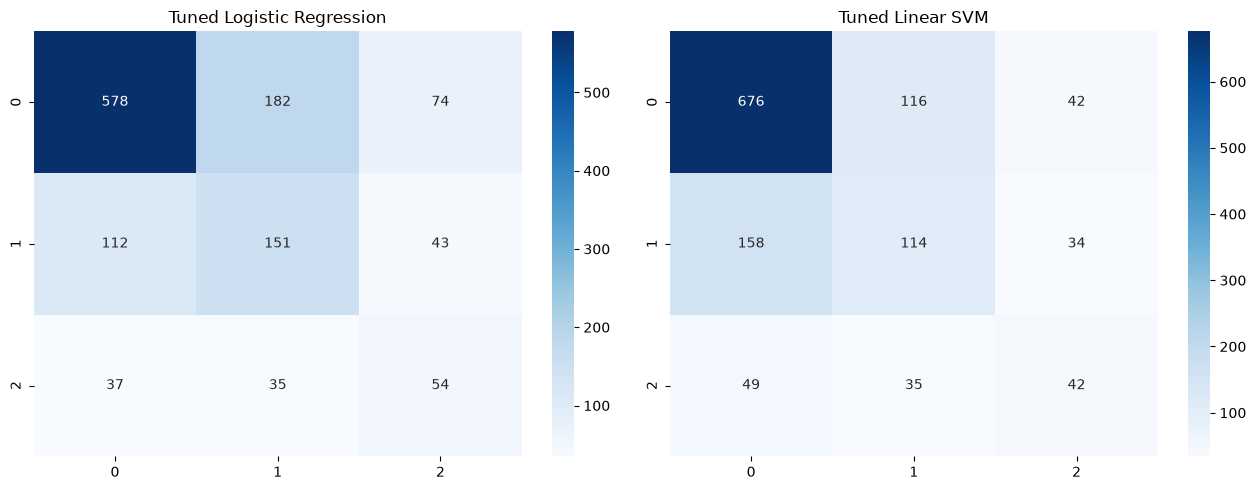

In [67]:
#Visualizations of the confusion matrices 

labels = ["0", "1", "2"]
cm_lr = confusion_matrix(y_test, y_pred_tuned, labels=labels)
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, cm, title in [
    (axes[0], cm_lr, "Tuned Logistic Regression"),
    (axes[1], cm_svm, "Tuned Linear SVM")
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()



###  Tuned Linear SVM Test Evaluation

The tuned Linear SVM was evaluated on the reserved test set of 1,266 records.

The model achieved:
- Accuracy: 65.72%
- Macro-F1: 0.5103

Per-class F1-scores were 0.79 for label 0, 0.40 for label 1, and 0.34 for label 2.

The SVM achieved higher test accuracy than the tuned Logistic Regression model (65.72% compared with 61.85%), but its macro-F1 was lower (0.5103 compared with 0.5174). This indicate the SVM's overall accuracy improvement did not translate into better balanced performance across the three numeric classes.



#### Training the Random Forest Model

In [69]:

#  Random Forest with TF-IDF features

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

rf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        max_features=3000,
        min_df=2,
        ngram_range=(1, 1),
        sublinear_tf=True
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1
    ))
])

# Five-fold stratified cross-validation on training data only
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_train_rf = X_train.reset_index(drop=True)
y_train_rf = y_train.reset_index(drop=True)

rf_scores = cross_val_score(
    rf_pipeline,
    X_train_rf,
    y_train_rf,
    scoring="f1_macro",
    cv=rf_cv,
    n_jobs=1
)

print("Random Forest cross-validation macro-F1 scores:")
print(rf_scores.round(4))

print("\nMean macro-F1:", round(rf_scores.mean(), 4))
print("Standard deviation:", round(rf_scores.std(), 4))


Random Forest cross-validation macro-F1 scores:
[0.5319 0.5261 0.5445 0.5289 0.5323]

Mean macro-F1: 0.5328
Standard deviation: 0.0063


###  Random Forest Evaluation

A Random Forest classifier using TF-IDF features was evaluated using five-fold stratified cross-validation on the training set.

The model achieved a mean macro-F1 of **0.5328**, with a standard deviation of **0.0063** across the five folds.

The Random Forest result was lower than the tuned Linear SVM mean macro-F1 of 0.5534 and the tuned Logistic Regression result of 0.5469. Although Random Forest performance was relatively consistent across folds, it did not outperform the linear classifiers in this experiment.

The comparison supports retaining Linear SVM as the leading candidate based on cross-validation. All results concern the original numeric labels, whose semantic meanings remain unverified.

In [ ]:

import sys
import importlib.util

print("Python version:", sys.version)

packages = ["torch", "transformers", "datasets", "accelerate"]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

if importlib.util.find_spec("torch"):
    import torch
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
    else:
        print("Running on CPU")


Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
torch: Not installed
transformers: Not installed
datasets: Not installed
accelerate: Not installed


In [84]:

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("\nTraining label counts:")
print(y_train.value_counts().sort_index())

print("\nMissing training texts:", X_train.isna().sum())
print("Missing training labels:", y_train.isna().sum())
print("Text column type:", X_train.dtype)


Training records: 5062
Test records: 1266

Training label counts:
Label
0    3333
1    1226
2     503
Name: count, dtype: int64

Missing training texts: 0
Missing training labels: 0
Text column type: str


In [85]:
import importlib.util
import subprocess
import sys

required = ["torch", "transformers", "datasets", "accelerate"]
missing = [name for name in required if importlib.util.find_spec(name) is None]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing
    ])
import torch
import transformers
import datasets
import accelerate
import sys
import subprocess

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.14.1+cpu
Transformers: 5.20.2
Datasets: 5.1.0
Accelerate: 1.15.0
CUDA available: False


### Error Analysis

In [86]:
# Build a table of the test examples and model predictions
error_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual_label": y_test.reset_index(drop=True).astype(str),
    "predicted_label": pd.Series(y_pred_svm).astype(str)
})

error_df["is_error"] = (
    error_df["actual_label"] != error_df["predicted_label"]
)

print("Total test examples:", len(error_df))
print("Incorrect predictions:", error_df["is_error"].sum())
print(
    "Error rate:",
    round(error_df["is_error"].mean() * 100, 2),
    "%"
)

print("\nErrors by actual label:")
display(
    error_df[error_df["is_error"]]
    .groupby("actual_label")
    .size()
    .rename("error_count")
    .to_frame()
)

print("\nFirst 20 misclassified examples:")
display(
    error_df.loc[
        error_df["is_error"],
        ["text", "actual_label", "predicted_label"]
    ].head(20)
)

Total test examples: 1266
Incorrect predictions: 434
Error rate: 34.28 %

Errors by actual label:


,error_count
actual_label,
0,158
1,192
2,84



First 20 misclassified examples:


,text,actual_label,predicted_label
1,kwanza uolewe umekomaa,1,0
2,"Wakenya wa kabila fulani ni wezi, wanafadhili Uhuru kuharibu nchi!",2,1
4,Wakenya. mnadanganyika hiyo hotuba ya Raila siyo mahala pale. Heshima ni ya watu wazee hajaonyesha heshima kwa Rais na katiba ya Kenya. Kama mgeni hiyo ndiyo naona wazi wazi bila upendeleo.,1,0
8,infact mbaya polisi bila sare wahalifu wahalifu gans sare ya jinai ujumbe,0,1
13,licha ya kwamba mwanafunzi wa moi ni mwalimu amesahau ukweli wanafunzi anashughulika tena kusambaza silabasi za zamani ngumu udikteta unahusika na nimeenda.,1,0
15,"Oxygen pekee ndiyo tusichotozwa, kila kitu kingine kina ushuru mkubwa.",2,0
17,salasya boy starting like thought angekuwa miongoni mwa watu wa kwanza kuyumbayumba kenya kwanza statehouse money first timer far good tu,1,0
21,"Baba tuko sawa, acha Zakayo aibe, maumivu yanafika Bondo na Ishaweri kwa kasi.",2,1
24,raila mwana fight nchi lipa hata bei ya mwisho hakikisha afisa wa serikali haramu ushindi lazima urudi,0,1
25,grandfathers coward sleepy people grabbing wealth wazungu independence nyanza would rich hatunge dharauliwa hivi na kunyanganywa usindi yetu kila siku,1,2


In [87]:
# Most common error types 
errors = error_df[error_df["is_error"]].copy()

errors["error_type"] = (
"Actual " + errors["actual_label"]
+ " predicted as " + errors["predicted_label"]
)

print("Most frequent error types:")
display(
errors["error_type"]
.value_counts()
.rename_axis("error_type")
.reset_index(name="count")
)

print("\nError counts by actual/predicted pair:")
display(
pd.crosstab(
errors["actual_label"],
errors["predicted_label"]
)
)



Most frequent error types:


,error_type,count
0,Actual 1 predicted as 0,158
1,Actual 0 predicted as 1,116
2,Actual 2 predicted as 0,49
3,Actual 0 predicted as 2,42
4,Actual 2 predicted as 1,35
5,Actual 1 predicted as 2,34



Error counts by actual/predicted pair:


predicted_label,0,1,2
actual_label,,,
0,0,116,42
1,158,0,34
2,49,35,0


In [88]:
# Saving the errors
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

error_path = output_dir / "khs_svm_test_errors.csv"

errors.to_csv(error_path, index=False, encoding="utf-8-sig")

print("Saved test errors to:", error_path.resolve())


Saved test errors to: C:\Users\Nicole Kasiva\OneDrive\Documents\data\processed\khs_svm_test_errors.csv


In [89]:
# Examine the most frequent types of SVM errors

error_summary = (
errors.groupby(["actual_label", "predicted_label"])
.agg(
error_count=("text", "size"),
example_text=("text", "first")
)
.reset_index()
.sort_values("error_count", ascending=False)
)

display(error_summary)


,actual_label,predicted_label,error_count,example_text
2,1,0,158,kwanza uolewe umekomaa
0,0,1,116,infact mbaya polisi bila sare wahalifu wahalifu gans sare ya jinai ujumbe
4,2,0,49,"Oxygen pekee ndiyo tusichotozwa, kila kitu kingine kina ushuru mkubwa."
1,0,2,42,"Sisi sio wajinga, tunajua nani hatalipi ushuru, wanaolipa ni maskini tu barabarani."
5,2,1,35,"Wakenya wa kabila fulani ni wezi, wanafadhili Uhuru kuharibu nchi!"
3,1,2,34,grandfathers coward sleepy people grabbing wealth wazungu independence nyanza would rich hatunge dharauliwa hivi na kunyanganywa usindi yetu kila siku


In [90]:
sample_errors = errors.sample(
n=min(20, len(errors)),
random_state=42
)

for _, row in sample_errors.iterrows():
    print("-" * 80)
    print("Text:", row["text"])
    print("Actual label:", row["actual_label"]) 
    print("Predicted label:", row["predicted_label"])


--------------------------------------------------------------------------------
Text: Kulipa ushuru ni kujitegemea, umesahau? Pesa hazipandwi kwa mti, serikali inahitaji mapato.
Actual label: 2
Predicted label: 0
--------------------------------------------------------------------------------
Text: Nakubaliana nawe, lakini ni Uhuru na kitendawili waliharibu, sasa Zakayo anamaliza.
Actual label: 2
Predicted label: 1
--------------------------------------------------------------------------------
Text: Kwa maoni yangu, subiri Wakenya wanaodaiwa kuwa wanafanya shughuli za kilimo waanze maandamano wakilalamikia bei ya juu ya unga ingekuwa suluhisho bora maonyesho ya kilimo yahamasishe watu washiriki kilimo mr kulaaniwa rao
Actual label: 2
Predicted label: 0
--------------------------------------------------------------------------------
Text: asante sana juhudi za raila kuokoa nchi ya kiimla serikali isiyo na akili hitaji siku nzima leo kenya marehemu sana asante kibinafsi
Actual label: 1

In [91]:
sample_errors = errors.sample(
n=min(20, len(errors)),
random_state=42
)

for _, row in sample_errors.iterrows():
    print("-" * 80)
    print("Text:", row["text"])
    print("Actual label:", row["actual_label"])
    print("Predicted label:", row["predicted_label"])


--------------------------------------------------------------------------------
Text: Kulipa ushuru ni kujitegemea, umesahau? Pesa hazipandwi kwa mti, serikali inahitaji mapato.
Actual label: 2
Predicted label: 0
--------------------------------------------------------------------------------
Text: Nakubaliana nawe, lakini ni Uhuru na kitendawili waliharibu, sasa Zakayo anamaliza.
Actual label: 2
Predicted label: 1
--------------------------------------------------------------------------------
Text: Kwa maoni yangu, subiri Wakenya wanaodaiwa kuwa wanafanya shughuli za kilimo waanze maandamano wakilalamikia bei ya juu ya unga ingekuwa suluhisho bora maonyesho ya kilimo yahamasishe watu washiriki kilimo mr kulaaniwa rao
Actual label: 2
Predicted label: 0
--------------------------------------------------------------------------------
Text: asante sana juhudi za raila kuokoa nchi ya kiimla serikali isiyo na akili hitaji siku nzima leo kenya marehemu sana asante kibinafsi
Actual label: 1

In [92]:
#Calculating the error rate in percentages 
import pandas as pd

class_error_analysis = (
error_df.groupby("actual_label")
.agg(
total_examples=("is_error", "size"),
incorrect_predictions=("is_error", "sum")
)
)

class_error_analysis["error_rate_percent"] = (
class_error_analysis["incorrect_predictions"]
/ class_error_analysis["total_examples"] * 100
).round(2)

display(class_error_analysis)

,total_examples,incorrect_predictions,error_rate_percent
actual_label,,,
0,834,158,18.94
1,306,192,62.75
2,126,84,66.67


In [93]:
# Prepare the transformer data
import pandas as pd

class_error_analysis = (
error_df.groupby("actual_label")
.agg(
total_examples=("is_error", "size"),
incorrect_predictions=("is_error", "sum")
)
)

class_error_analysis["error_rate_percent"] = (
class_error_analysis["incorrect_predictions"]
/ class_error_analysis["total_examples"] * 100
).round(2)

display(class_error_analysis)

,total_examples,incorrect_predictions,error_rate_percent
actual_label,,,
0,834,158,18.94
1,306,192,62.75
2,126,84,66.67


In [ ]:
import torch
import transformers
import datasets
import accelerate

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Training will run on CPU")

PyTorch: 2.14.1+cpu
Transformers: 5.20.2
Datasets: 5.1.0
Accelerate: 1.15.0
CUDA available: False
Training will run on CPU


In [94]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
model_name,
num_labels=3
)

print("Tokenizer loaded successfully.")
print("Model loaded successfully.")
print("Number of output classes:", model.config.num_labels)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 421.19it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tokenizer loaded successfully.
Model loaded successfully.
Number of output classes: 3


In [95]:
import pandas as pd
from pathlib import Path

# Your CSV files are in the project root folder
data_dir = Path.cwd()

train_df = pd.read_csv(data_dir / "khs_train.csv")
test_df = pd.read_csv(data_dir / "khs_test.csv")
clean_df = pd.read_csv(data_dir / "khs_preliminary_clean.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)
print("Clean dataset shape:", clean_df.shape)

print("\nTraining columns:", train_df.columns.tolist())
print("Testing columns:", test_df.columns.tolist())

print("\nTraining dataset preview:")
display(train_df.head())

print("\nTesting dataset preview:")
display(test_df.head())


Training dataset shape: (5062, 2)
Testing dataset shape: (1266, 2)
Clean dataset shape: (6328, 2)

Training columns: ['Text', 'Label']
Testing columns: ['Text', 'Label']

Training dataset preview:


,Text,Label
0,"""Polisi wetu baba"" wanachama wa azimio wanataka endelea na safari jumatatu ijayo tuko maaandamano",1
1,risasi saba za moja kwa moja za karibu lengo lililokosa haileti maana,0
2,hakuna kama kamanda mkuu,1
3,Usajili wa gari ni bandia sana,0
4,"Hii ilikuwa yenye ufahamu mkubwa na ilijaa masomo ya kina yatakayobaki nasi kwa muda mrefu. Pumzika kwa raha kamili, Jakom, urithi wako unaendelea kutuongoza.",0



Testing dataset preview:


,Text,Label
0,jua plan bwana odinga fast one going open server,0
1,kwanza uolewe umekomaa,1
2,"Wakenya wa kabila fulani ni wezi, wanafadhili Uhuru kuharibu nchi!",2
3,kazi nzuri baba msamaha wako umepokea umethibitisha bwana,0
4,Wakenya. mnadanganyika hiyo hotuba ya Raila siyo mahala pale. Heshima ni ya watu wazee hajaonyesha heshima kwa Rais na katiba ya Kenya. Kama mgeni hiyo ndiyo naona wazi wazi bila upendeleo.,1


In [96]:
# Restore the variables needed for modelling

X_train = train_df["Text"].astype(str)
y_train = train_df["Label"].astype(str)

X_test = test_df["Text"].astype(str)
y_test = test_df["Label"].astype(str)

print("Training text records:", len(X_train))
print("Training labels:", len(y_train))
print("Testing text records:", len(X_test))
print("Testing labels:", len(y_test))

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting label distribution:")
print(y_test.value_counts().sort_index())

print("\nMissing training texts:", X_train.isna().sum())
print("Missing testing texts:", X_test.isna().sum())

Training text records: 5062
Training labels: 5062
Testing text records: 1266
Testing labels: 1266

Training label distribution:
Label
0    3333
1    1226
2     503
Name: count, dtype: int64

Testing label distribution:
Label
0    834
1    306
2    126
Name: count, dtype: int64

Missing training texts: 0
Missing testing texts: 0


In [98]:
%pip install huggingface_hub
from pathlib import Path
from huggingface_hub import try_to_load_from_cache

model_name = "FacebookAI/xlm-roberta-base"

files_to_check = [
    "config.json",
    "tokenizer_config.json",
    "sentencepiece.bpe.model",
    "model.safetensors",
    "pytorch_model.bin"
]

print("Checking local Hugging Face model cache...\n")

for filename in files_to_check:
    try:
        result = try_to_load_from_cache(
            repo_id=model_name,
            filename=filename
        )

        if isinstance(result, Path):
            print(f"FOUND: {filename}")
        else:
            print(f"NOT FOUND: {filename}")

    except Exception as e:
        print(f"Could not check {filename}: {e}")
        try:
            result = try_to_load_from_cache(
                repo_id=model_name,
                filename=filename
            )

            if isinstance(result, Path):
                print(f"FOUND: {filename}")
            else:
                print(f"NOT FOUND: {filename}")
        except Exception as e2:
            print(f"Could not re-check {filename}: {e2}")


Note: you may need to restart the kernel to use updated packages.
Checking local Hugging Face model cache...

NOT FOUND: config.json
NOT FOUND: tokenizer_config.json
NOT FOUND: sentencepiece.bpe.model
NOT FOUND: model.safetensors
NOT FOUND: pytorch_model.bin



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [99]:
print("Checking local Hugging Face model cache...\n")

for filename in files_to_check:
	try:
		result = try_to_load_from_cache(
			repo_id=model_name,
			filename=filename
		)

		if isinstance(result, Path):
			print(f"FOUND: {filename}")
		else:
			print(f"NOT FOUND: {filename}")

	except Exception as e:
		print(f"Could not check {filename}: {e}")


Checking local Hugging Face model cache...

NOT FOUND: config.json
NOT FOUND: tokenizer_config.json
NOT FOUND: sentencepiece.bpe.model
NOT FOUND: model.safetensors
NOT FOUND: pytorch_model.bin


In [100]:
from huggingface_hub import model_info

try:
	info = model_info("FacebookAI/xlm-roberta-base")
	print("Connection successful!")
	print("Model:", info.modelId)
	print("The model is available to download.")
except Exception as e:
	print("Connection or model access failed:")
	print(type(e).__name__, str(e)[:500])

Connection successful!
Model: FacebookAI/xlm-roberta-base
The model is available to download.


In [101]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "FacebookAI/xlm-roberta-base"

print("Downloading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
print("Tokenizer downloaded successfully!")

print("Downloading model weights...")
model = AutoModelForSequenceClassification.from_pretrained(
model_name,
num_labels=3
)
print("Model loaded successfully!")
print("Number of output classes:", model.config.num_labels)

Tokenizer downloaded successfully!


OSError: The paging file is too small for this operation to complete. (os error 1455)

In [102]:

from pathlib import Path
import pandas as pd

# Locate the project folder
project_dir = Path.cwd()

print("Current folder:", project_dir)

# Restore the saved datasets
train_path = project_dir / "khs_train.csv"
test_path = project_dir / "khs_test.csv"
clean_path = project_dir / "khs_preliminary_clean.csv"

if all(p.exists() for p in [train_path, test_path, clean_path]):
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
    clean_df = pd.read_csv(clean_path)

    print("\nDatasets restored successfully!")
    print("Training data:", train_df.shape)
    print("Testing data:", test_df.shape)
    print("Cleaned data:", clean_df.shape)
    print("\nColumns:", train_df.columns.tolist())
else:
    print("\nOne or more CSV files were not found.")
    print("Files in the current folder:")
    print([p.name for p in project_dir.glob("*.csv")])


Current folder: c:\Users\Nicole Kasiva\OneDrive\Documents\Election_Violence_Early_Detection_System

Datasets restored successfully!
Training data: (5062, 2)
Testing data: (1266, 2)
Cleaned data: (6328, 2)

Columns: ['Text', 'Label']


In [103]:

print("TRAINING LABEL DISTRIBUTION")
print(train_df["Label"].value_counts().sort_index())

print("\nTESTING LABEL DISTRIBUTION")
print(test_df["Label"].value_counts().sort_index())

print("\nLABEL DATA TYPE:", train_df["Label"].dtype)

print("\nSAMPLE RECORDS")
display(train_df.head())


TRAINING LABEL DISTRIBUTION
Label
0    3333
1    1226
2     503
Name: count, dtype: int64

TESTING LABEL DISTRIBUTION
Label
0    834
1    306
2    126
Name: count, dtype: int64

LABEL DATA TYPE: int64

SAMPLE RECORDS


,Text,Label
0,"""Polisi wetu baba"" wanachama wa azimio wanataka endelea na safari jumatatu ijayo tuko maaandamano",1
1,risasi saba za moja kwa moja za karibu lengo lililokosa haileti maana,0
2,hakuna kama kamanda mkuu,1
3,Usajili wa gari ni bandia sana,0
4,"Hii ilikuwa yenye ufahamu mkubwa na ilijaa masomo ya kina yatakayobaki nasi kwa muda mrefu. Pumzika kwa raha kamili, Jakom, urithi wako unaendelea kutuongoza.",0


In [104]:
# checking for label meanings
from pathlib import Path
import pandas as pd

project_dir = Path.cwd()

annotation_path = project_dir / "khs_manual_annotation_sample.csv"

if annotation_path.exists():
    annotations = pd.read_csv(annotation_path, encoding="cp1252")

    print("Shape:", annotations.shape)
    print("Columns:", annotations.columns.tolist())
    display(annotations.head(10))
else:
    print("Annotation sample file not found.")


Shape: (90, 6)
Columns: ['record_id', 'Text', 'manual_category', 'confidence', 'notes', 'Unnamed: 5']


,record_id,Text,manual_category,confidence,notes,Unnamed: 5
0,R001,"Viongozi waliochaguliwa wa odm wajiuzulu kutafuta mamlaka mapya kwa kutumia iebc tofauti, kwa kweli",Unclear,Low,Fragmentary political statement; intent and context are unclear.,NaN
1,R002,wages sin death leave demonstrations kifo itakupata,Offensive,Medium,Threatening phrase about death; target and context are unclear.,NaN
2,R003,noti moja muhimu picha zilizopigwa mwelekeo upande viti vitupu ama wapinzani,Neutral,Low,Fragmentary statement about a photo/opponents; no clear targeted abuse in the excerpt.,NaN
3,R004,hakuna msaada,Neutral,Medium,Short statement meaning 'no help'; no clear abuse or hate target.,NaN
4,R005,"Mheshimiwa, barabara hii itakuwa moja ya urithi wako mkubwa zaidi. Ni mradi unaohitajika sana, muhimu sana kwa Wakenya. Ifanye iwe nzuri",Neutral,High,Positive comment about a public infrastructure project.,NaN
5,R006,kutokea viongozi wahuni kulazimisha nafasi za uongozi,Offensive,Low,"Calls leaders hooligans; insulting wording, but context is limited.",NaN
6,R007,lawama afisa wa polisi alikosa lengo kifungo cha maisha jela,Unclear,Low,Fragment about a police officer and punishment; meaning is incomplete.,NaN
7,R008,Amekuwa akikosa lakini anawafadhili..hakuna haja ya msamaha wowote.,Offensive,Medium,Accusatory criticism and refusal to forgive; no protected group targeted.,NaN
8,R009,Mimi ni mtaalamu wa tiba ya kisaikolojia na najua maadili ya kazi yanahitaji mteja apelekwe kwa mtaalamu mwingine inapobidi.,Neutral,High,Professional/ethical statement unrelated to targeted abuse.,NaN
9,R010,"Ushuru wa bidhaa za urembo uwe hata 1000%, tumekuwa cowdung kwa muda mrefu, acha tusaidie serikali yetu.",Offensive,Low,Sarcastic/derogatory political-economic comment; wording partly unclear.,NaN


In [105]:

# Compare manual annotations with original numeric labels

print("Manual annotation categories:")
print(annotations["manual_category"].value_counts(dropna=False))

print("\nNumeric labels in the cleaned dataset:")
print(clean_df["Label"].value_counts().sort_index())

print("\nAnnotation sample columns:")
print(annotations.columns.tolist())


Manual annotation categories:
manual_category
Offensive      31
Neutral        30
Unclear        22
Hate Speech     7
Name: count, dtype: int64

Numeric labels in the cleaned dataset:
Label
0    4167
1    1532
2     629
Name: count, dtype: int64

Annotation sample columns:
['record_id', 'Text', 'manual_category', 'confidence', 'notes', 'Unnamed: 5']


In [106]:

import pandas as pd

# Make temporary copies for comparison
manual = annotations[["Text", "manual_category"]].copy()
numeric = clean_df[["Text", "Label"]].copy()

# Normalize text for matching
manual["match_text"] = (
    manual["Text"].fillna("").astype(str).str.strip().str.lower()
)
numeric["match_text"] = (
    numeric["Text"].fillna("").astype(str).str.strip().str.lower()
)

# Match annotated posts to their numeric labels
matched = manual.merge(
    numeric[["match_text", "Label"]].drop_duplicates(),
    on="match_text",
    how="inner"
)

print("Matched annotation records:", len(matched))

print("\nManual category versus numeric label:")
display(pd.crosstab(matched["manual_category"], matched["Label"]))

print("\nUnmatched annotation records:", len(manual) - len(matched))


Matched annotation records: 87

Manual category versus numeric label:


Label,0,1,2
manual_category,,,
Hate Speech,0,2,5
Neutral,15,9,6
Offensive,6,13,9
Unclear,9,5,8



Unmatched annotation records: 3


In [107]:

from pathlib import Path
import json
import joblib

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Prepare existing datasets
X_train = train_df["Text"].fillna("").astype(str)
y_train = train_df["Label"].astype(int)

X_test = test_df["Text"].fillna("").astype(str)
y_test = test_df["Label"].astype(int)

# 2. Create the baseline classifier
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=20000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=500,
        random_state=42
    ))
])

# 3. Train
print("Training baseline model...")
baseline_model.fit(X_train, y_train)
print("Training completed!")

# 4. Evaluate on the held-out test data
y_pred = baseline_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"\nTest accuracy: {accuracy:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred, labels=[0, 1, 2], zero_division=0
))

print("Confusion matrix (labels 0, 1, 2):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1, 2]))

# 5. Save model and metrics separately
project_dir = Path.cwd()
artifact_dir = project_dir / "artifacts"
artifact_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    baseline_model,
    artifact_dir / "baseline_model.joblib"
)

metrics = {
    "model": "TF-IDF + Logistic Regression",
    "test_accuracy": float(accuracy),
    "test_records": int(len(y_test)),
    "labels": [0, 1, 2]
}

with open(artifact_dir / "evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("\nSaved model:", artifact_dir / "baseline_model.joblib")
print("Saved metrics:", artifact_dir / "evaluation_metrics.json")


Training baseline model...
Training completed!

Test accuracy: 0.6864

Classification report:
              precision    recall  f1-score   support

           0       0.70      0.95      0.81       834
           1       0.52      0.20      0.29       306
           2       0.70      0.13      0.21       126

    accuracy                           0.69      1266
   macro avg       0.64      0.43      0.44      1266
weighted avg       0.66      0.69      0.62      1266

Confusion matrix (labels 0, 1, 2):
[[791  39   4]
 [241  62   3]
 [ 92  18  16]]

Saved model: c:\Users\Nicole Kasiva\OneDrive\Documents\Election_Violence_Early_Detection_System\artifacts\baseline_model.joblib
Saved metrics: c:\Users\Nicole Kasiva\OneDrive\Documents\Election_Violence_Early_Detection_System\artifacts\evaluation_metrics.json


###  Confirm the modelling split and class distribution



In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize

# Reuse the original split created earlier in this notebook.
# If those variables are unavailable after a kernel restart, reconstruct a reproducible stratified split.
try:
    X_train = X_train.fillna("").astype(str)
    X_test = X_test.fillna("").astype(str)
    y_train = y_train.astype(str)
    y_test = y_test.astype(str)
    print("Using the existing notebook train/test split.")
except NameError:
    modelling_df = pd.read_csv("khs_preliminary_clean.csv", dtype={"Label": str})
    modelling_df["Text"] = modelling_df["Text"].fillna("").astype(str)
    X_train, X_test, y_train, y_test = train_test_split(
        modelling_df["Text"], modelling_df["Label"],
        test_size=0.20, random_state=42, stratify=modelling_df["Label"]
    )
    print("Existing split variables were unavailable; created a stratified 80/20 split with random_state=42.")

labels = sorted(pd.Series(y_train).astype(str).unique().tolist())
print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("\nTraining label proportions:")
display(y_train.value_counts(normalize=True).sort_index().mul(100).round(2).rename("Percentage").to_frame())
print("\nTest label proportions:")
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2).rename("Percentage").to_frame())

Using the existing notebook train/test split.
Training records: 5062
Test records: 1266

Training label proportions:


,Percentage
Label,
0,65.84
1,24.22
2,9.94



Test label proportions:


,Percentage
Label,
0,65.88
1,24.17
2,9.95


###  Text preprocessing used for modelling



In [109]:
preprocessing_summary = pd.DataFrame({
    "Check": [
        "Missing training texts",
        "Empty training texts after trimming",
        "Mean training word count",
        "Median training word count",
        "Mean training character count"
    ],
    "Result": [
        int(pd.Series(X_train).isna().sum()),
        int(pd.Series(X_train).str.strip().eq("").sum()),
        round(pd.Series(X_train).str.split().str.len().mean(), 2),
        round(pd.Series(X_train).str.split().str.len().median(), 2),
        round(pd.Series(X_train).str.len().mean(), 2)
    ]
})
display(preprocessing_summary)

def make_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )

,Check,Result
0,Missing training texts,0.00
1,Empty training texts after trimming,0.00
2,Mean training word count,15.34
3,Median training word count,13.00
4,Mean training character count,100.56


###  Multinomial Naive Bayes



In [110]:
nb_model = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", MultinomialNB())
])
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

print("Multinomial Naive Bayes")
print("Accuracy:", round(accuracy_score(y_test, nb_pred), 4))
print("Macro-F1:", round(f1_score(y_test, nb_pred, average="macro"), 4))
print(classification_report(y_test, nb_pred, labels=labels, zero_division=0))

Multinomial Naive Bayes
Accuracy: 0.6864
Macro-F1: 0.3772
              precision    recall  f1-score   support

           0       0.69      0.99      0.81       834
           1       0.62      0.13      0.22       306
           2       1.00      0.06      0.11       126

    accuracy                           0.69      1266
   macro avg       0.77      0.39      0.38      1266
weighted avg       0.70      0.69      0.60      1266



###  Class weighting for Logistic Regression and Linear SVM



In [111]:
balanced_lr_model = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ))
])
balanced_svm_model = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", LinearSVC(
        class_weight="balanced", random_state=42
    ))
])

balanced_models = {
    "Multinomial Naive Bayes": nb_model,
    "Logistic Regression (balanced)": balanced_lr_model,
    "Linear SVM (balanced)": balanced_svm_model
}

balanced_results = []
balanced_predictions = {}
for model_name, model in balanced_models.items():
    if model_name != "Multinomial Naive Bayes":
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    balanced_predictions[model_name] = pred
    p, r, f, _ = precision_recall_fscore_support(
        y_test, pred, labels=labels, average="macro", zero_division=0
    )
    balanced_results.append({
        "Model": model_name,
        "Test accuracy": accuracy_score(y_test, pred),
        "Macro precision": p,
        "Macro recall": r,
        "Macro-F1": f,
        "Weighted-F1": f1_score(y_test, pred, average="weighted")
    })

balanced_results_df = pd.DataFrame(balanced_results).sort_values("Macro-F1", ascending=False)
display(balanced_results_df.round(4))

,Model,Test accuracy,Macro precision,Macro recall,Macro-F1,Weighted-F1
1,Logistic Regression (balanced),0.6035,0.4948,0.5282,0.5054,0.6179
2,Linear SVM (balanced),0.6414,0.5028,0.5040,0.5034,0.6417
0,Multinomial Naive Bayes,0.6864,0.7679,0.3906,0.3772,0.5966


###  Threshold adjustment using validation data



In [112]:
X_fit, X_val, y_fit, y_val = train_test_split(
    pd.Series(X_train).reset_index(drop=True),
    pd.Series(y_train).reset_index(drop=True),
    test_size=0.20, random_state=43, stratify=pd.Series(y_train).reset_index(drop=True)
)

threshold_lr = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ))
])
threshold_lr.fit(X_fit, y_fit)
val_probs = threshold_lr.predict_proba(X_val)
class_names = list(threshold_lr.named_steps["classifier"].classes_)

# Candidate thresholds for each class; choose by validation macro-F1 only.
threshold_grid = [0.20, 0.30, 0.40, 0.50]
best_thresholds = {c: 0.0 for c in class_names}
best_val_f1 = -1

# Coordinate search: optimize one class threshold at a time while holding the others fixed.
# Baseline argmax is retained as a fallback if thresholding does not improve validation macro-F1.
def threshold_predict(probabilities, classes, thresholds):
    adjusted = probabilities.copy()
    for j, cls in enumerate(classes):
        adjusted[:, j] = adjusted[:, j] - thresholds[cls]
    return np.asarray(classes)[adjusted.argmax(axis=1)]

val_base_pred = np.asarray(class_names)[val_probs.argmax(axis=1)]
best_val_f1 = f1_score(y_val, val_base_pred, average="macro")
best_thresholds = {c: 0.0 for c in class_names}

improved = True
for _ in range(3):
    improved = False
    for cls in class_names:
        current_best = best_thresholds[cls]
        for t in threshold_grid:
            trial = best_thresholds.copy()
            trial[cls] = t
            trial_pred = threshold_predict(val_probs, class_names, trial)
            score = f1_score(y_val, trial_pred, average="macro")
            if score > best_val_f1 + 1e-6:
                best_val_f1 = score
                best_thresholds = trial
                current_best = t
                improved = True

print("Validation baseline macro-F1:", round(f1_score(y_val, val_base_pred, average="macro"), 4))
print("Selected class thresholds:", best_thresholds)
print("Best validation macro-F1 found:", round(best_val_f1, 4))

# Refit on all training data, then evaluate once on the untouched test set.
threshold_lr.fit(X_train, y_train)
test_probs = threshold_lr.predict_proba(X_test)
threshold_test_pred = threshold_predict(test_probs, class_names, best_thresholds)
default_test_pred = threshold_lr.predict(X_test)

threshold_comparison = pd.DataFrame([
    {
        "Decision rule": "Default probability argmax",
        "Test accuracy": accuracy_score(y_test, default_test_pred),
        "Test macro-F1": f1_score(y_test, default_test_pred, average="macro")
    },
    {
        "Decision rule": "Validation-tuned class thresholds",
        "Test accuracy": accuracy_score(y_test, threshold_test_pred),
        "Test macro-F1": f1_score(y_test, threshold_test_pred, average="macro")
    }
])
display(threshold_comparison.round(4))
print("Thresholds were selected on validation data, not on the test set.")

Validation baseline macro-F1: 0.5589
Selected class thresholds: {'0': 0.0, '1': 0.0, '2': 0.2}
Best validation macro-F1 found: 0.5727


,Decision rule,Test accuracy,Test macro-F1
0,Default probability argmax,0.6035,0.5054
1,Validation-tuned class thresholds,0.6256,0.5108


Thresholds were selected on validation data, not on the test set.


### 7. Learning curves



,Training examples,Mean training macro-F1,Mean CV macro-F1,CV standard deviation
0,843,0.9331,0.4770,0.0133
1,1687,0.9122,0.5202,0.0063
2,2530,0.8773,0.5229,0.0006
3,3374,0.8609,0.5352,0.0041


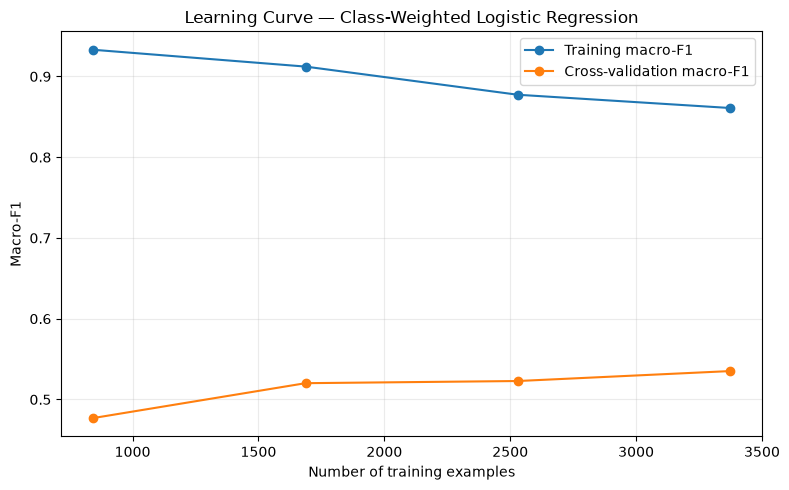

In [113]:
learning_model = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ))
])
learning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
train_sizes, train_scores, cv_scores = learning_curve(
    learning_model,
    pd.Series(X_train).reset_index(drop=True),
    pd.Series(y_train).reset_index(drop=True),
    cv=learning_cv,
    scoring="f1_macro",
    train_sizes=np.linspace(0.25, 1.0, 4),
    n_jobs=1
)
learning_curve_results = pd.DataFrame({
    "Training examples": train_sizes,
    "Mean training macro-F1": train_scores.mean(axis=1),
    "Mean CV macro-F1": cv_scores.mean(axis=1),
    "CV standard deviation": cv_scores.std(axis=1)
})
display(learning_curve_results.round(4))

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Training macro-F1")
plt.plot(train_sizes, cv_scores.mean(axis=1), marker="o", label="Cross-validation macro-F1")
plt.xlabel("Number of training examples")
plt.ylabel("Macro-F1")
plt.title("Learning Curve — Class-Weighted Logistic Regression")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Model explainability

In [114]:
explain_model = balanced_lr_model
feature_names = explain_model.named_steps["tfidf"].get_feature_names_out()
classifier = explain_model.named_steps["classifier"]
explain_rows = []

for class_index, class_name in enumerate(classifier.classes_):
    coef = classifier.coef_[class_index]
    top_indices = np.argsort(coef)[-15:][::-1]
    for rank, feature_index in enumerate(top_indices, start=1):
        explain_rows.append({
            "Numeric class": class_name,
            "Rank": rank,
            "TF-IDF term": feature_names[feature_index],
            "Coefficient": coef[feature_index]
        })

explainability_df = pd.DataFrame(explain_rows)
for class_name in classifier.classes_:
    print(f"Top terms associated with numeric class {class_name}:")
    display(explainability_df[explainability_df["Numeric class"] == class_name].head(15).round(4))

Top terms associated with numeric class 0:


,Numeric class,Rank,TF-IDF term,Coefficient
0,0,1,daima,1.3674
1,0,2,mungu,1.3442
2,0,3,kumbuka,1.3388
3,0,4,tafadhali,1.1870
4,0,5,nawe,1.1593
5,0,6,upendo,1.1282
6,0,7,katika,1.1157
7,0,8,kevin,1.0838
8,0,9,amani,1.0757
9,0,10,wangu,1.0583


Top terms associated with numeric class 1:


,Numeric class,Rank,TF-IDF term,Coefficient
15,1,1,majambazi,1.7657
16,1,2,brigade,1.3721
17,1,3,aibu,1.3494
18,1,4,mapema,1.2946
19,1,5,huruma,1.2436
20,1,6,uongo,1.2264
21,1,7,wanasiasa,1.1817
22,1,8,watu,1.1722
23,1,9,luos,1.1673
24,1,10,uhuru,1.1664


Top terms associated with numeric class 2:


,Numeric class,Rank,TF-IDF term,Coefficient
30,2,1,ni,2.7617
31,2,2,tu,2.7012
32,2,3,kwa kweli,2.6762
33,2,4,hawa,2.3339
34,2,5,wacha,2.1667
35,2,6,mswada,2.1076
36,2,7,sana,2.0879
37,2,8,wapelekwe,2.0389
38,2,9,ushuru,2.0298
39,2,10,kupinga,1.8783


### Error analysis for the selected Linear SVM



In [115]:
error_analysis_df = pd.DataFrame({
    "Text": pd.Series(X_test).reset_index(drop=True),
    "Actual label": pd.Series(y_test).reset_index(drop=True).astype(str),
    "Predicted label": pd.Series(balanced_predictions["Linear SVM (balanced)"]).astype(str)
})
error_analysis_df["Correct"] = error_analysis_df["Actual label"] == error_analysis_df["Predicted label"]
errors_only = error_analysis_df.loc[~error_analysis_df["Correct"]].copy()

print("Test records:", len(error_analysis_df))
print("Incorrect predictions:", len(errors_only))
print("Error rate:", round(len(errors_only) / len(error_analysis_df), 4))

print("\nMost common error pairs:")
error_pairs = (
    errors_only.groupby(["Actual label", "Predicted label"])
    .size().reset_index(name="Count")
    .sort_values("Count", ascending=False)
)
display(error_pairs)

print("\nExample errors (first 15):")
display(errors_only.head(15))

Test records: 1266
Incorrect predictions: 454
Error rate: 0.3586

Most common error pairs:


,Actual label,Predicted label,Count
2,1,0,143
0,0,1,136
1,0,2,56
4,2,0,48
5,2,1,38
3,1,2,33



Example errors (first 15):


,Text,Actual label,Predicted label,Correct
1,kwanza uolewe umekomaa,1,0,False
2,"Wakenya wa kabila fulani ni wezi, wanafadhili Uhuru kuharibu nchi!",2,1,False
4,Wakenya. mnadanganyika hiyo hotuba ya Raila siyo mahala pale. Heshima ni ya watu wazee hajaonyesha heshima kwa Rais na katiba ya Kenya. Kama mgeni hiyo ndiyo naona wazi wazi bila upendeleo.,1,0,False
6,Tunawapolea kwa dhati familia zilizoathiriwa na tukio hili la kusikitisha sana.,0,1,False
8,infact mbaya polisi bila sare wahalifu wahalifu gans sare ya jinai ujumbe,0,1,False
13,licha ya kwamba mwanafunzi wa moi ni mwalimu amesahau ukweli wanafunzi anashughulika tena kusambaza silabasi za zamani ngumu udikteta unahusika na nimeenda.,1,0,False
15,"Oxygen pekee ndiyo tusichotozwa, kila kitu kingine kina ushuru mkubwa.",2,0,False
17,salasya boy starting like thought angekuwa miongoni mwa watu wa kwanza kuyumbayumba kenya kwanza statehouse money first timer far good tu,1,0,False
21,"Baba tuko sawa, acha Zakayo aibe, maumivu yanafika Bondo na Ishaweri kwa kasi.",2,1,False
22,aha leo si kuzungumza uporaji mortuary,0,2,False


In [116]:
RUN_XLM_ROBERTA = False  # Change to True only when the environment has the required packages and compute.

if not RUN_XLM_ROBERTA:
    print("XLM-RoBERTa training skipped. Previous work only confirmed setup/model availability checks; no completed evaluation result is available.")
else:
    try:
        import torch
        from datasets import Dataset
        from transformers import (
            AutoTokenizer, AutoModelForSequenceClassification,
            TrainingArguments, Trainer
        )
        from sklearn.preprocessing import LabelEncoder

        label_encoder = LabelEncoder()
        y_train_enc = label_encoder.fit_transform(pd.Series(y_train).astype(str))
        y_test_enc = label_encoder.transform(pd.Series(y_test).astype(str))
        X_fit_xlm, X_val_xlm, y_fit_xlm, y_val_xlm = train_test_split(
            list(pd.Series(X_train).astype(str)), list(y_train_enc),
            test_size=0.15, random_state=42, stratify=list(y_train_enc)
        )

        model_name = "FacebookAI/xlm-roberta-base"
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModelForSequenceClassification.from_pretrained(
            model_name, num_labels=len(label_encoder.classes_)
        )

        def tokenize_batch(batch):
            return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=128)

        train_ds = Dataset.from_dict({"text": X_fit_xlm, "label": y_fit_xlm}).map(tokenize_batch, batched=True)
        val_ds = Dataset.from_dict({"text": X_val_xlm, "label": y_val_xlm}).map(tokenize_batch, batched=True)
        test_ds = Dataset.from_dict({"text": list(pd.Series(X_test).astype(str)), "label": list(y_test_enc)}).map(tokenize_batch, batched=True)

        args = TrainingArguments(
            output_dir="./xlmr_results",
            eval_strategy="epoch",
            save_strategy="no",
            learning_rate=2e-5,
            per_device_train_batch_size=8,
            per_device_eval_batch_size=8,
            num_train_epochs=2,
            weight_decay=0.01,
            report_to="none"
        )

        def compute_metrics(eval_pred):
            logits, true_labels = eval_pred
            pred_labels = np.argmax(logits, axis=1)
            return {
                "accuracy": accuracy_score(true_labels, pred_labels),
                "macro_f1": f1_score(true_labels, pred_labels, average="macro")
            }

        trainer = Trainer(
            model=model, args=args, train_dataset=train_ds,
            eval_dataset=val_ds, compute_metrics=compute_metrics
        )
        trainer.train()
        xlmr_metrics = trainer.evaluate(test_ds)
        print("XLM-RoBERTa held-out test metrics:", xlmr_metrics)
        print("Encoded numeric label order:", list(label_encoder.classes_))
    except Exception as exc:
        print("XLM-RoBERTa experiment did not complete:", repr(exc))
        print("Record this as incomplete rather than reporting performance numbers.")

XLM-RoBERTa training skipped. Previous work only confirmed setup/model availability checks; no completed evaluation result is available.


###  Final model comparison table



In [117]:
final_comparison = balanced_results_df.copy()
final_comparison["Experiment split"] = "Current notebook split; balanced/additional models"
display(final_comparison.sort_values("Macro-F1", ascending=False).round(4))

print("Existing notebook results (recorded earlier; preserve as separate experiments):")
print("- Tuned Logistic Regression: test accuracy 61.85%, test macro-F1 0.5174; CV macro-F1 0.5469.")
print("- Tuned Linear SVM: test accuracy 65.72%, test macro-F1 0.5103; CV macro-F1 0.5534.")
print("- Random Forest: mean five-fold CV macro-F1 0.5328.")
print("Do not combine these numbers with the new table unless the exact same split and settings were used.")

,Model,Test accuracy,Macro precision,Macro recall,Macro-F1,Weighted-F1,Experiment split
1,Logistic Regression (balanced),0.6035,0.4948,0.5282,0.5054,0.6179,Current notebook split; balanced/additional models
2,Linear SVM (balanced),0.6414,0.5028,0.5040,0.5034,0.6417,Current notebook split; balanced/additional models
0,Multinomial Naive Bayes,0.6864,0.7679,0.3906,0.3772,0.5966,Current notebook split; balanced/additional models


Existing notebook results (recorded earlier; preserve as separate experiments):
- Tuned Logistic Regression: test accuracy 61.85%, test macro-F1 0.5174; CV macro-F1 0.5469.
- Tuned Linear SVM: test accuracy 65.72%, test macro-F1 0.5103; CV macro-F1 0.5534.
- Random Forest: mean five-fold CV macro-F1 0.5328.
Do not combine these numbers with the new table unless the exact same split and settings were used.


### SHAP EXPLAINABILITY

In [ ]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 1.8 MB/s  0:00:00

   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ------

In [71]:
import shap

vectorizer = best_svm_model.named_steps["tfidf"]
classifier = best_svm_model.named_steps["classifier"]

background_text = X_train.sample(
n=min(50, len(X_train)),
random_state=42
)

sample_text = X_test.sample(
n=min(10, len(X_test)),
random_state=42
)

background_matrix = vectorizer.transform(background_text)

sample_matrix = vectorizer.transform(sample_text)

explainer = shap.LinearExplainer(
classifier,
background_matrix
)

shap_values = explainer(sample_matrix)

print("SHAP analysis completed.")

SHAP analysis completed.


SHAP explanation for Label 0


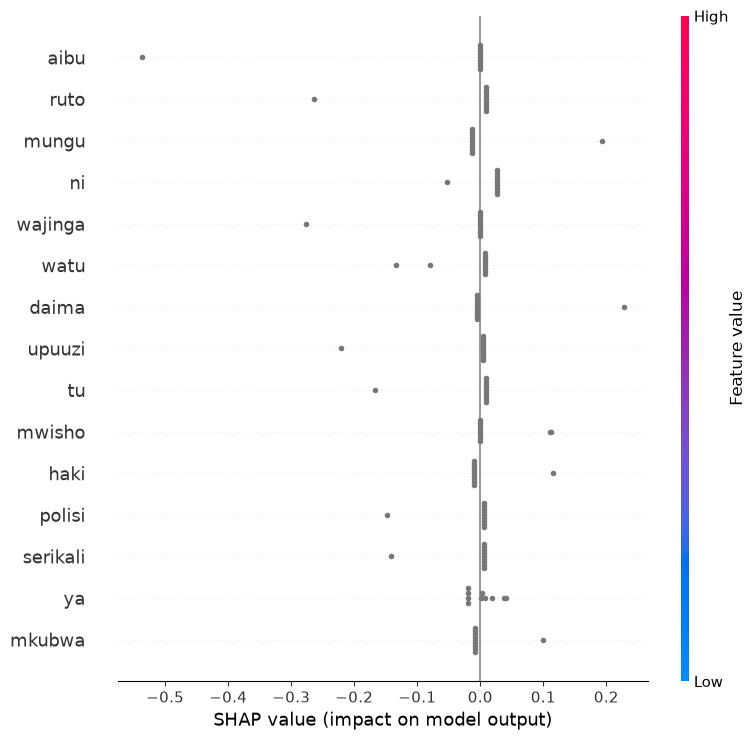

SHAP explanation for Label 1


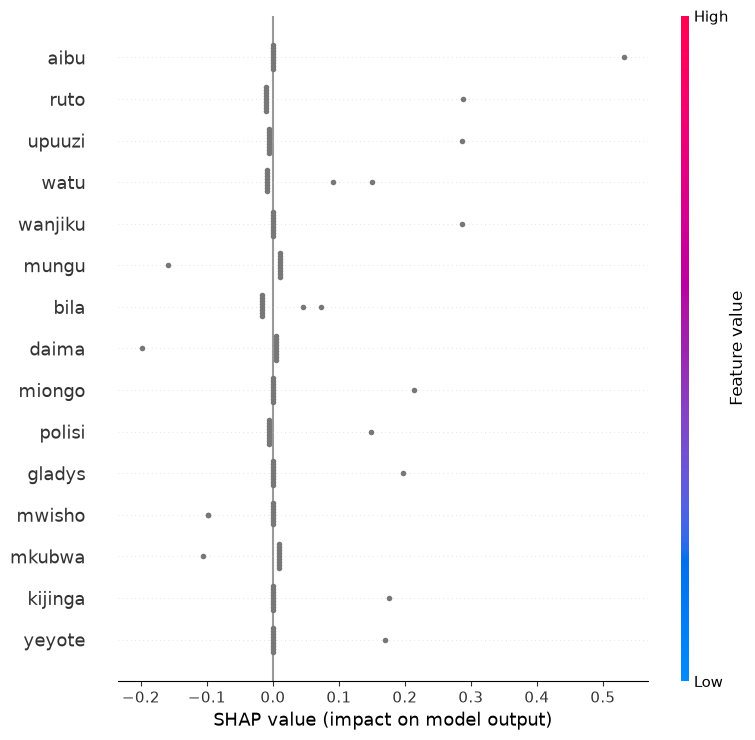

SHAP explanation for Label 2


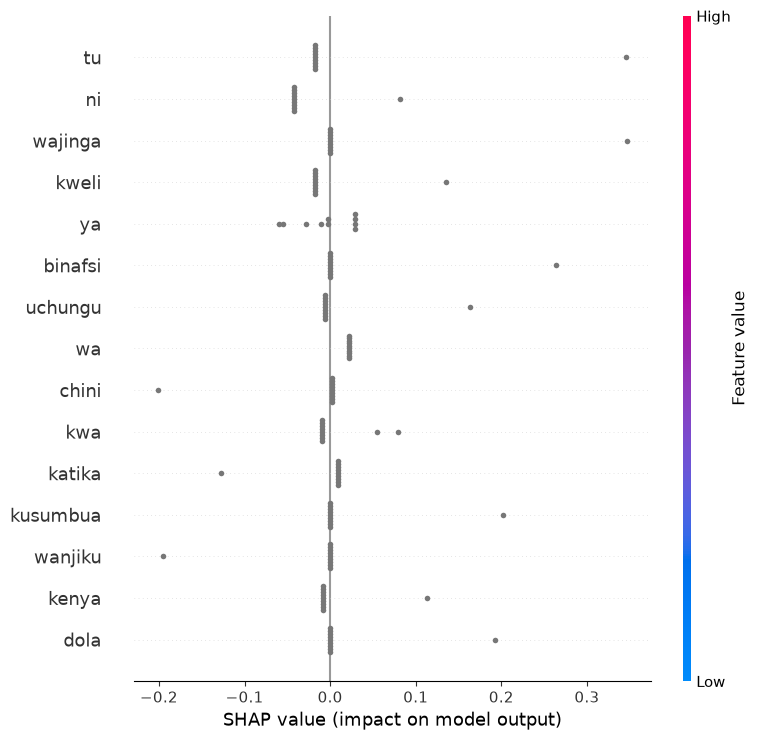

In [73]:
# specific class visualization

classes = best_svm_model.named_steps["classifier"].classes_
feature_names = best_svm_model.named_steps["tfidf"].get_feature_names_out()

for class_index, label in enumerate(classes):
	print(f"SHAP explanation for Label {label}")

	shap.summary_plot(
		shap_values.values[:, :, class_index],
		sample_matrix,
		feature_names=feature_names,
		max_display=15
	)

In [77]:
# Extracting misclassified records 

balanced_lr_model = Pipeline([
	("tfidf", TfidfVectorizer(
		lowercase=True,
		max_features=5000,
		ngram_range=(1, 2),
		min_df=2,
		sublinear_tf=True
	)),
	("classifier", LogisticRegression(
		max_iter=2000, class_weight="balanced", random_state=42
	))
])
balanced_lr_model.fit(X_train, y_train)

y_pred = balanced_lr_model.predict(X_test)
y_prob = balanced_lr_model.predict_proba(X_test)

misclassified = pd.DataFrame({
"Text": pd.Series(X_test).reset_index(drop=True),
"Actual Label": pd.Series(y_test).reset_index(drop=True),
"Predicted Label": y_pred,
"Prediction Confidence": y_prob.max(axis=1)
})

misclassified = misclassified[
misclassified["Actual Label"] !=
misclassified["Predicted Label"]
]

print("Number of misclassified records:", len(misclassified))

display(misclassified.head(30))


Number of misclassified records: 502


,Text,Actual Label,Predicted Label,Prediction Confidence
0,jua plan bwana odinga fast one going open server,0,1,0.471756
1,kwanza uolewe umekomaa,1,0,0.542403
8,infact mbaya polisi bila sare wahalifu wahalifu gans sare ya jinai ujumbe,0,1,0.751920
13,licha ya kwamba mwanafunzi wa moi ni mwalimu amesahau ukweli wanafunzi anashughulika tena kusambaza silabasi za zamani ngumu udikteta unahusika na nimeenda.,1,0,0.722453
16,bado idadi nzuri hata bila,0,1,0.512565
17,salasya boy starting like thought angekuwa miongoni mwa watu wa kwanza kuyumbayumba kenya kwanza statehouse money first timer far good tu,1,0,0.508647
18,uhuru mkweli mungu ambariki uhuru k,0,1,0.474709
21,"Baba tuko sawa, acha Zakayo aibe, maumivu yanafika Bondo na Ishaweri kwa kasi.",2,1,0.643301
24,raila mwana fight nchi lipa hata bei ya mwisho hakikisha afisa wa serikali haramu ushindi lazima urudi,0,1,0.443526
25,grandfathers coward sleepy people grabbing wealth wazungu independence nyanza would rich hatunge dharauliwa hivi na kunyanganywa usindi yetu kila siku,1,2,0.542200


In [78]:
# count the types of missclassification 

misclassified["Error Type"] = (
misclassified["Actual Label"].astype(str)
+ " → "
+ misclassified["Predicted Label"].astype(str)
)

error_summary = (
misclassified["Error Type"]
.value_counts()
.reset_index()
)

error_summary.columns = [
"Actual → Predicted",
"Number of Errors"
]

display(error_summary)


,Actual → Predicted,Number of Errors
0,0 → 1,187
1,1 → 0,120
2,0 → 2,82
3,1 → 2,42
4,2 → 0,38
5,2 → 1,33


In [118]:
# storing the results in a database 

import sqlite3

connection = sqlite3.connect(
	"khs_analysis_results.db"
)

# Top 20 words per class
class_word_frequency_df = (
	normalized_freq
	.sort_values(["Label", "Count"], ascending=[True, False])
	.groupby("Label")
	.head(20)[["Label", "Word", "Count"]]
	.rename(columns={"Count": "Frequency"})
)
class_word_frequency_df.to_sql(
	"class_word_frequency",
	connection,
	if_exists="replace",
	index=False
)

# Store text feature audit (Series)
text_feature_audit.rename("Count").rename_axis("Feature").reset_index().to_sql(
	"text_feature_audit",
	connection,
	if_exists="replace",
	index=False
)

# Store learning curve results when available
if "learning_curve_results" in globals():
	learning_curve_results.to_sql(
		"learning_curve_results",
		connection,
		if_exists="replace",
		index=False
	)
else:
	print("Learning curve results not available; run the learning curve cell to store them.")

# Store explainability coefficients
explainability_df.to_sql(
	"logistic_coefficients",
	connection,
	if_exists="replace",
	index=False
)

# Store misclassified records
misclassified.to_sql(
	"misclassifications",
	connection,
	if_exists="replace",
	index=False
)

connection.close()

print("Analysis results successfully stored in SQLite.")

Analysis results successfully stored in SQLite.


In [120]:
# Exporting the results 
from pathlib import Path

output_folder = Path("supplementary_analysis_outputs")
output_folder.mkdir(exist_ok=True)

if "class_word_frequency_df" in globals():
	class_word_frequency_df.to_csv(
		output_folder / "class_word_frequency.csv",
		index=False
	)

if "text_feature_audit" in globals():
	text_feature_audit.rename("Count").rename_axis("Feature").reset_index().to_csv(
		output_folder / "text_feature_audit.csv",
		index=False
	)

if "learning_curve_results" in globals():
	learning_curve_results.to_csv(
		output_folder / "learning_curve_results.csv",
		index=False
	)

if "explainability_df" in globals():
	explainability_df.to_csv(
		output_folder / "logistic_coefficients.csv",
		index=False
	)

if "misclassified" in globals():
	misclassified.to_csv(
		output_folder / "misclassified_statements.csv",
		index=False
	)

if "comparison_df" in globals():
	comparison_df.to_csv(
		output_folder / "original_cleaned_comparison.csv",
		index=False
	)

print("Available supplementary results exported successfully.")

Available supplementary results exported successfully.
